# 0. SETUP

In [1]:
pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optuna]


In [2]:
pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 57.2 MB/s  0:00:01


In [7]:
import math
import pickle
import platform
import re
import warnings

from pathlib import Path
import difflib

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display
from scipy import stats
from scipy.optimize import minimize
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint

from sklearn import set_config
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.feature_selection import (
    RFE,
    SelectFromModel,
    SelectPercentile,
    chi2,
    f_classif,
    mutual_info_classif,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict,
    cross_val_score,
    cross_validate,
    train_test_split,
)
from sklearn.neighbors import LocalOutlierFactor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    MinMaxScaler,
    OneHotEncoder,
    RobustScaler,
    SplineTransformer,
    StandardScaler,
    label_binarize,
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.validation import check_is_fitted

from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler

import optuna

try:
    from lightgbm import LGBMClassifier
except ImportError:
    LGBMClassifier = None

try:
    from xgboost import XGBClassifier
except ImportError:
    XGBClassifier = None

try:
    from catboost import CatBoostClassifier
except ImportError:
    CatBoostClassifier = None

try:
    import shap
except ImportError:
    shap = None

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
set_config(transform_output="pandas")
optuna.logging.set_verbosity(optuna.logging.WARNING)

RANDOM_STATE = 42
N_JOBS = 2
SKLEARN_VERSION = tuple(int(part) for part in sklearn.__version__.split(".")[:2])
rng = np.random.default_rng(RANDOM_STATE)

print("scikit-learn:", sklearn.__version__)
print("LightGBM:", LGBMClassifier is not None,
      "| XGBoost:", XGBClassifier is not None,
      "| CatBoost:", CatBoostClassifier is not None,
      "| SHAP:", shap is not None)

scikit-learn: 1.6.1
LightGBM: True | XGBoost: True | CatBoost: True | SHAP: True


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
# Dataset Configuration — Give Me Some Credit

DATA_PATH = "/content/drive/MyDrive/Datasets/Give Me Some Credit/cs-training.csv"
TEST_PATH = "/content/drive/MyDrive/Datasets/Give Me Some Credit/cs-test.csv"
SAMPLE_SUBMISSION_PATH = "/content/drive/MyDrive/Datasets/Give Me Some Credit/sampleEntry.csv"

# Target variable
TARGET = "SeriousDlqin2yrs"

# Columns excluded from model training
DROP_COLS = ["Unnamed: 0"]

# Binary classification: 1 = Serious Delinquency
POSITIVE_CLASS = 1

# No categorical-coded features
CATEGORICAL_CODED_COLS = []

# CSV files do not require an Excel header offset
EXCEL_HEADER = 0

# 1. LOAD DATA & TASK DEFINITION

In [8]:
def check_columns(names, available, label):
    """Validate column names and provide suggestions for typos."""
    missing = [c for c in names if c not in available]

    if not missing:
        return

    lookup = {str(c).lower(): c for c in available}
    hints = {}

    for name in missing:
        match = difflib.get_close_matches(
            str(name).lower(),
            list(lookup),
            n=1,
            cutoff=0.6
        )
        if match:
            hints[name] = lookup[match[0]]

    raise KeyError(
        f"{label}: column(s) not found: {missing}. "
        + (f"Did you mean {hints}? " if hints else "")
        + f"Available columns: {list(available)}"
    )


# Load training and Kaggle test datasets
df = pd.read_csv(DATA_PATH)
df_test = pd.read_csv(TEST_PATH)

# Validate training dataset
if TARGET not in df.columns:
    raise KeyError(f"Target '{TARGET}' not found in training data.")

check_columns(DROP_COLS, df.columns, "DROP_COLS")
check_columns(DROP_COLS, df_test.columns, "TEST DROP_COLS")
check_columns(CATEGORICAL_CODED_COLS,df.columns,"CATEGORICAL_CODED_COLS")

# Preserve Kaggle test IDs for final submission
test_ids = df_test["Unnamed: 0"].copy()

# Kaggle test target must be entirely missing
if TARGET in df_test.columns:
    if df_test[TARGET].notna().any():
        raise ValueError("Kaggle test contains non-missing target values.")

# Remove ID columns and test target
df = df.drop(columns=DROP_COLS)
df_test = df_test.drop(columns=DROP_COLS + [TARGET], errors="ignore")

# Remove rows with missing training labels
df = df.dropna(subset=[TARGET]).reset_index(drop=True)

# Validate duplicate column names
if df.columns.duplicated().any() or df_test.columns.duplicated().any():
    raise ValueError("Duplicate column names are not supported.")


class CodedCategoryCaster(BaseEstimator, TransformerMixin):
    """Convert integer-coded categorical features to string labels."""

    def __init__(self, columns=None):
        self.columns = columns

    def fit(self, X, y=None):
        return self

    @staticmethod
    def to_label(value):
        try:
            if pd.isna(value):
                return np.nan
        except (TypeError, ValueError):
            pass

        try:
            number = float(value)
            if number.is_integer():
                return str(int(number))
        except (TypeError, ValueError):
            pass

        return str(value)

    def transform(self, X):
        X = X.copy()

        for col in self.columns or []:
            if col in X.columns:
                X[col] = X[col].map(self.to_label).astype(object)

        return X


# Apply categorical conversion consistently
coded_cols = [c for c in CATEGORICAL_CODED_COLS if c != TARGET]
caster = CodedCategoryCaster(coded_cols)

df = caster.transform(df)
df_test = caster.transform(df_test)

# Ensure training and Kaggle test features match
train_features = df.drop(columns=[TARGET]).columns.tolist()
test_features = df_test.columns.tolist()

if set(train_features) != set(test_features):
    raise ValueError("Training and test feature columns do not match.")

df_test = df_test[train_features]

# Dataset summary
print("Training Shape:", df.shape)
print("Test Shape:", df_test.shape)
print("Number of Features:", len(train_features))

print("\nTraining Data:")
display(df.head())

print("\nTest Data:")
display(df_test.head())

Training Shape: (150000, 11)
Test Shape: (101503, 10)
Number of Features: 10

Training Data:


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0



Test Data:


,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,0.885519,43,0,0.177513,5700.0,4,0,0,0,0.0
1,0.463295,57,0,0.527237,9141.0,15,0,4,0,2.0
2,0.043275,59,0,0.687648,5083.0,12,0,1,0,2.0
3,0.280308,38,1,0.925961,3200.0,7,0,2,0,0.0
4,1.000000,27,0,0.019917,3865.0,4,0,0,0,1.0


In [10]:
class_counts = df[TARGET].value_counts()
N_CLASSES = class_counts.size

if N_CLASSES < 2:
    raise ValueError(f"'{TARGET}' must contain at least two classes.")

IS_BINARY = N_CLASSES == 2

# Encode target as 0..K-1 (binary: positive class = 1)
if IS_BINARY:
    positive = POSITIVE_CLASS if POSITIVE_CLASS is not None else class_counts.idxmin()
    if positive not in class_counts.index:
        raise ValueError(f"POSITIVE_CLASS={positive!r} not found in '{TARGET}'.")
    CLASS_NAMES = [c for c in class_counts.index if c != positive] + [positive]
else:
    CLASS_NAMES = sorted(class_counts.index.tolist(), key=str)

CLASS_TO_CODE = {c: i for i, c in enumerate(CLASS_NAMES)}
CLASS_LABELS = [str(c) for c in CLASS_NAMES]
df[TARGET] = df[TARGET].map(CLASS_TO_CODE).astype(int)

# Task-dependent CV scoring
if IS_BINARY:
    SCORING = {
        "average_precision": "average_precision",
        "roc_auc": "roc_auc",
        "f1_macro": "f1_macro",
        "balanced_accuracy": "balanced_accuracy",
        "accuracy": "accuracy",
    }
    PRIMARY_METRIC = "roc_auc"
else:
    SCORING = {
        "f1_macro": "f1_macro",
        "roc_auc_ovr": "roc_auc_ovr",
        "balanced_accuracy": "balanced_accuracy",
        "neg_log_loss": "neg_log_loss",
        "accuracy": "accuracy",
    }
    PRIMARY_METRIC = "f1_macro"

print("Task:", "Binary" if IS_BINARY else f"Multiclass ({N_CLASSES} classes)")
print("Class encoding:", {label: code for code, label in enumerate(CLASS_LABELS)})
print("Primary CV metric:", PRIMARY_METRIC)

Task: Binary
Class encoding: {'0': 0, '1': 1}
Primary CV metric: roc_auc


In [11]:
def display_data_schema(data):
    schema = pd.DataFrame({
        "dtype": data.dtypes.astype(str),
        "missing_count": data.isna().sum(),
        "missing_rate": data.isna().mean(),
        "n_unique": data.nunique(dropna=True),
    }).sort_values(["missing_rate", "n_unique"], ascending=[False, False])
    return schema


features_all = df.drop(columns=[TARGET])
display(display_data_schema(features_all))

constant_cols = [
    c for c in features_all.columns
    if features_all[c].nunique(dropna=True) <= 1
]

id_like_cols = [
    c for c in features_all.columns
    if features_all[c].nunique(dropna=True) == len(df)
    and not pd.api.types.is_float_dtype(features_all[c])
]

print("Rows:", len(df))
print("Columns:", features_all.shape[1])
print("Exact duplicate rows:", df.duplicated().sum())
print("Constant columns:", constant_cols)
print("ID-like columns:", id_like_cols)

,dtype,missing_count,missing_rate,n_unique
MonthlyIncome,float64,29731,0.198207,13594
NumberOfDependents,float64,3924,0.026160,13
RevolvingUtilizationOfUnsecuredLines,float64,0,0.000000,125728
DebtRatio,float64,0,0.000000,114194
age,int64,0,0.000000,86
NumberOfOpenCreditLinesAndLoans,int64,0,0.000000,58
NumberRealEstateLoansOrLines,int64,0,0.000000,28
NumberOfTimes90DaysLate,int64,0,0.000000,19
NumberOfTime30-59DaysPastDueNotWorse,int64,0,0.000000,16
NumberOfTime60-89DaysPastDueNotWorse,int64,0,0.000000,13


Rows: 150000
Columns: 10
Exact duplicate rows: 609
Constant columns: []
ID-like columns: []


Total Observations: 150,000
Imbalance Ratio (max/min): 13.961:1
Majority-Class Accuracy: 93.32%


,Class,Count,Percentage
0,0,139974,93.316
1,1,10026,6.684


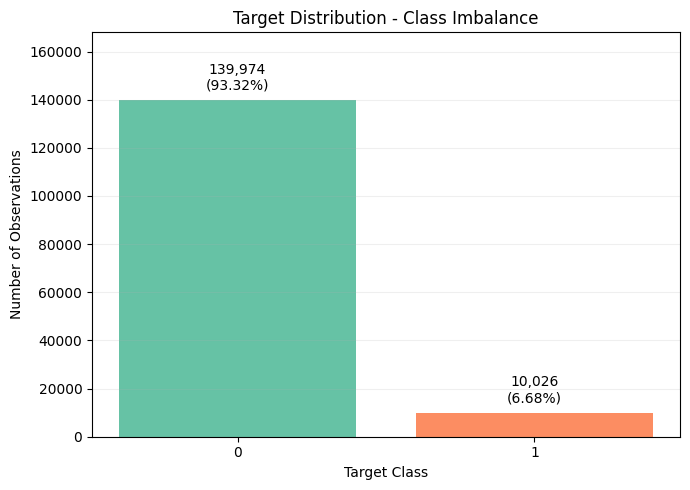

In [12]:
def target_imbalance_diagnostics(y):

    counts = y.value_counts().sort_index()
    proportions = counts / counts.sum()

    summary = pd.DataFrame({
        "Class": [CLASS_LABELS[i] for i in counts.index],
        "Count": counts.values,
        "Percentage": proportions.values * 100,
    })

    print(f"Total Observations: {len(y):,}")
    print(f"Imbalance Ratio (max/min): {counts.max() / counts.min():.3f}:1")
    print(f"Majority-Class Accuracy: {counts.max() / counts.sum():.2%}")
    display(summary.round(3))

    fig, ax = plt.subplots(figsize=(max(7, 1.5 * len(counts)), 5))

    bars = ax.bar(
        summary["Class"],
        summary["Count"],
        color=sns.color_palette("Set2", len(counts)),
    )

    ax.bar_label(
        bars,
        labels=[
            f"{count:,}\n({pct:.2f}%)"
            for count, pct in zip(summary["Count"], summary["Percentage"])
        ],
        padding=5,
    )

    ax.set_title("Target Distribution - Class Imbalance")
    ax.set_xlabel("Target Class")
    ax.set_ylabel("Number of Observations")
    ax.set_ylim(0, counts.max() * 1.2)
    ax.grid(axis="y", alpha=0.2)

    plt.tight_layout()
    plt.show()

    return summary


target_summary = target_imbalance_diagnostics(df[TARGET])

# 2. Stratified Train-Test Split

In [13]:
TEST_SIZE = 0.20

X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE,
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

target_distribution = pd.DataFrame({
    "Full Dataset": y.value_counts(normalize=True),
    "Train": y_train.value_counts(normalize=True),
    "Test": y_test.value_counts(normalize=True),
}).sort_index() * 100

target_distribution.index = [CLASS_LABELS[i] for i in target_distribution.index]
display(target_distribution.round(3))

X_train: (120000, 10)
X_test: (30000, 10)


,Full Dataset,Train,Test
0,93.316,93.316,93.317
1,6.684,6.684,6.683


# 3. Leakage / Availability Audit (training data only)

## 3.1 Target-Dependent Missingness

In [14]:
LEAK_MISSING_GAP = 0.30  # max - min missing rate across classes


def missingness_by_class(X, y):

    cols = [c for c in X.columns if X[c].isna().any()]

    if not cols:
        return pd.DataFrame(columns=["Gap_pp"])

    table = X[cols].isna().groupby(y).mean().T * 100
    table.columns = [f"Missing_%_{CLASS_LABELS[c]}" for c in table.columns]
    table["Gap_pp"] = table.max(axis=1) - table.min(axis=1)

    return table.sort_values("Gap_pp", ascending=False)


missing_audit = missingness_by_class(X_train, y_train)
display(missing_audit.round(2))

missing_leak_cols = missing_audit.index[
    missing_audit["Gap_pp"] >= LEAK_MISSING_GAP * 100
].tolist()

print("Flagged by missingness:", missing_leak_cols)

,Missing_%_0,Missing_%_1,Gap_pp
MonthlyIncome,19.96,16.44,3.52
NumberOfDependents,2.67,1.72,0.95


Flagged by missingness: []


## 3.2 Near-Pure Categories

In [15]:
CATEGORY_MIN_COUNT = 10
CATEGORY_PURITY = 0.99
PURITY_P_VALUE = 1e-6  # binomial tail probability of such purity under the class prior


def category_purity_audit(X, y):

    priors = y.value_counts(normalize=True)
    rows = []

    for col in X.select_dtypes(exclude=np.number).columns:

        s = X[col].astype(object).fillna("<MISSING>").astype(str)
        ct = pd.crosstab(s, y)
        counts = ct.sum(axis=1)
        shares = ct.div(counts, axis=0)

        for category in ct.index:

            n = int(counts[category])

            if n < CATEGORY_MIN_COUNT:
                continue

            dominant = shares.loc[category].idxmax()
            purity = shares.loc[category, dominant]
            p_value = stats.binom.sf(ct.loc[category, dominant] - 1, n, priors[dominant])

            if purity >= CATEGORY_PURITY and p_value < PURITY_P_VALUE:
                rows.append({
                    "Feature": col,
                    "Category": category,
                    "Count": n,
                    "Dominant_Class": CLASS_LABELS[dominant],
                    "Purity_%": purity * 100,
                    "Class_Prior_%": priors[dominant] * 100,
                    "Binomial_P": p_value,
                })

    return pd.DataFrame(
        rows,
        columns=["Feature", "Category", "Count", "Dominant_Class",
                 "Purity_%", "Class_Prior_%", "Binomial_P"],
    )


purity_audit = category_purity_audit(X_train, y_train)
display(purity_audit)

purity_leak_cols = purity_audit["Feature"].unique().tolist()
print("Flagged by category purity:", purity_leak_cols)

,Feature,Category,Count,Dominant_Class,Purity_%,Class_Prior_%,Binomial_P


Flagged by category purity: []


## 3.3 Single-Feature Predictive Power

In [16]:
SINGLE_FEATURE_AUC = 0.95

def single_feature_power(X, y, n_splits=3):

    cv_audit = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    rows = []

    for col in X.columns:

        s = X[col]

        if s.nunique(dropna=True) <= 1:
            continue

        # Missing values get their own region so missingness itself is tested
        if pd.api.types.is_numeric_dtype(s):
            v = s.astype(float).replace([np.inf, -np.inf], np.nan)
            fill_value = v.min() - 1 if v.notna().any() else -1
            x = v.fillna(fill_value).to_frame()
        else:
            x = pd.Series(pd.factorize(s)[0], index=s.index).to_frame(col)

        tree = DecisionTreeClassifier(
            max_depth=4,
            min_samples_leaf=20,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        )

        proba = cross_val_predict(tree, x, y, cv=cv_audit, method="predict_proba")

        auc = (
            roc_auc_score(y, proba[:, 1])
            if IS_BINARY
            else roc_auc_score(y, proba, multi_class="ovr")
        )

        rows.append({"Feature": col, "Single_Feature_AUC": auc})

    return (
        pd.DataFrame(rows)
        .sort_values("Single_Feature_AUC", ascending=False)
        .reset_index(drop=True)
    )


power_audit = single_feature_power(X_train, y_train)
display(power_audit.round(4))

power_leak_cols = power_audit.loc[
    power_audit["Single_Feature_AUC"] >= SINGLE_FEATURE_AUC, "Feature"
].tolist()

print("Flagged by single-feature AUC:", power_leak_cols)

,Feature,Single_Feature_AUC
0,RevolvingUtilizationOfUnsecuredLines,0.7806
1,NumberOfTime30-59DaysPastDueNotWorse,0.6846
2,NumberOfTimes90DaysLate,0.6555
3,age,0.6289
4,NumberOfTime60-89DaysPastDueNotWorse,0.6206
5,DebtRatio,0.5815
6,MonthlyIncome,0.5782
7,NumberRealEstateLoansOrLines,0.5655
8,NumberOfOpenCreditLinesAndLoans,0.5609
9,NumberOfDependents,0.5473


Flagged by single-feature AUC: []


## 3.4 Feature Exclusion Summary

In [17]:
MANUAL_EXCLUDE = []        # confirmed leaks / features unavailable at prediction time
MANUAL_KEEP = []           # flagged or ID-like features reviewed and confirmed as legitimate
LEAKAGE_POLICY = "review"  # "review" | "exclude" | "keep"

check_columns(MANUAL_EXCLUDE + MANUAL_KEEP, X_train.columns, "MANUAL_EXCLUDE / MANUAL_KEEP")

warnings_by_feature = {}
for reason, cols in [
    ("constant", constant_cols),
    ("id-like", id_like_cols),
    ("class-dependent missingness (REVIEW)", missing_leak_cols),
    ("near-pure category (REVIEW)", purity_leak_cols),
    (f"single-feature AUC >= {SINGLE_FEATURE_AUC} (REVIEW)", power_leak_cols),
    ("manual exclusion", MANUAL_EXCLUDE),
]:
    for col in cols:
        warnings_by_feature.setdefault(col, []).append(reason)

# Target-independent drops: constant and ID-like columns
auto_drop = set(constant_cols) | set(id_like_cols)

# Target-dependent flags must be resolved explicitly
flagged = set(missing_leak_cols) | set(purity_leak_cols) | set(power_leak_cols)
unresolved = sorted(flagged - set(MANUAL_EXCLUDE) - set(MANUAL_KEEP))

if LEAKAGE_POLICY == "exclude":
    auto_drop |= set(unresolved)
elif LEAKAGE_POLICY not in ("review", "keep"):
    raise ValueError("LEAKAGE_POLICY must be 'review', 'exclude' or 'keep'.")

excluded_features = sorted((auto_drop | set(MANUAL_EXCLUDE)) - set(MANUAL_KEEP))


def leakage_action(col):
    if col in excluded_features:
        return "DROP"
    if col in MANUAL_KEEP:
        return "KEEP (reviewed)"
    if col in unresolved:
        return "UNRESOLVED" if LEAKAGE_POLICY == "review" else "KEEP (not reviewed)"
    return "KEEP"


leakage_review = (
    pd.DataFrame([
        {"Feature": col, "Reason": ", ".join(reasons), "Action": leakage_action(col)}
        for col, reasons in warnings_by_feature.items()
    ]).sort_values("Feature").reset_index(drop=True)
    if warnings_by_feature else pd.DataFrame(columns=["Feature", "Reason", "Action"])
)
display(leakage_review)

if unresolved and LEAKAGE_POLICY == "review":
    raise RuntimeError(
        f"Unresolved leakage flags: {unresolved}. Add each feature to MANUAL_EXCLUDE "
        "(leak / unavailable at prediction time) or MANUAL_KEEP (legitimate), "
        "or set LEAKAGE_POLICY = 'exclude'."
    )
if unresolved and LEAKAGE_POLICY == "keep":
    print("WARNING — flagged features kept without review:", unresolved)

X_eda = X_train.drop(columns=excluded_features)
numeric_cols = [c for c in X_eda.select_dtypes(include=np.number).columns if X_eda[c].nunique(dropna=True) > 1]
categorical_cols = X_eda.select_dtypes(exclude=np.number).columns.tolist()

print("Excluded features:", excluded_features)
print("Remaining features:", X_eda.shape[1])
print("Numerical:", len(numeric_cols), "| Categorical:", len(categorical_cols))

,Feature,Reason,Action


Excluded features: []
Remaining features: 10
Numerical: 10 | Categorical: 0


# 4. Numerical Features - Univariate Analysis

## 4.1 Descriptive Statistics, Skewness & Kurtosis

Continuous features: ['RevolvingUtilizationOfUnsecuredLines', 'age', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans']


,count,mean,std,min,Q1,median,Q3,max,IQR,missing_rate_%,skewness,excess_kurtosis
MonthlyIncome,96325.0,6651.507,14541.181,0.0,3400.000,5390.000,8238.000,3008750.0,4838.000,19.729,122.590,21862.370
RevolvingUtilizationOfUnsecuredLines,120000.0,6.129,253.361,0.0,0.030,0.153,0.558,50708.0,0.528,0.000,100.539,15560.223
DebtRatio,120000.0,352.271,2093.710,0.0,0.175,0.366,0.861,329664.0,0.686,0.000,99.144,14370.862
NumberOfTime60-89DaysPastDueNotWorse,120000.0,0.240,4.145,0.0,0.000,0.000,0.000,98.0,0.000,0.000,23.394,548.655
NumberOfTimes90DaysLate,120000.0,0.265,4.158,0.0,0.000,0.000,0.000,98.0,0.000,0.000,23.156,540.897
NumberOfTime30-59DaysPastDueNotWorse,120000.0,0.420,4.182,0.0,0.000,0.000,0.000,98.0,0.000,0.000,22.657,525.202
NumberRealEstateLoansOrLines,120000.0,1.018,1.133,0.0,0.000,1.000,2.000,54.0,2.000,0.000,3.753,71.091
NumberOfDependents,116872.0,0.757,1.115,0.0,0.000,0.000,1.000,20.0,1.000,2.607,1.599,3.179
NumberOfOpenCreditLinesAndLoans,120000.0,8.466,5.162,0.0,5.000,8.000,11.000,58.0,6.000,0.000,1.229,3.179
age,120000.0,52.288,14.771,0.0,41.000,52.000,63.000,109.0,22.000,0.000,0.186,-0.498


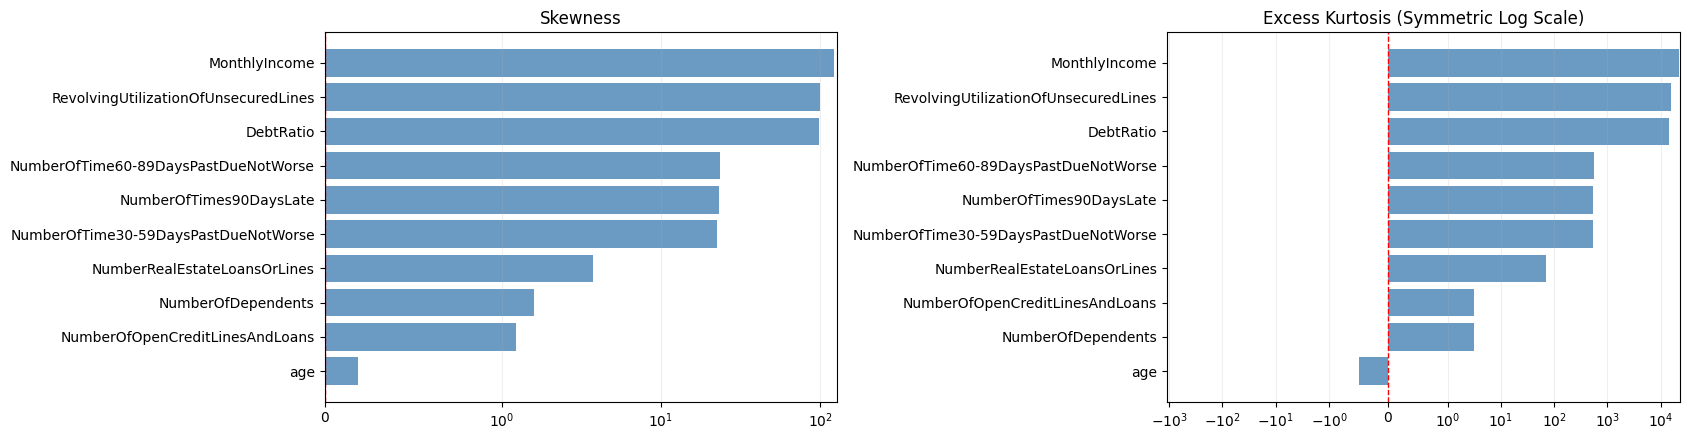

In [18]:
def is_integer_valued(s):
    s = s.dropna()
    return len(s) > 0 and np.allclose(s, np.round(s))


def is_discrete(s, max_unique=30):
    return s.nunique(dropna=True) <= max_unique and is_integer_valued(s)


def numeric_profile(data, cols):

    summary = data[cols].describe().T.rename(
        columns={"25%": "Q1", "50%": "median", "75%": "Q3"}
    )

    summary["IQR"] = summary["Q3"] - summary["Q1"]
    summary["missing_rate_%"] = data[cols].isna().mean() * 100
    summary["skewness"] = data[cols].skew()
    summary["excess_kurtosis"] = data[cols].kurt()

    return summary.sort_values("skewness", key=lambda s: s.abs(), ascending=False)


continuous_cols = [c for c in numeric_cols if not is_discrete(X_eda[c])]
print("Continuous features:", continuous_cols)

numeric_summary = numeric_profile(X_eda, numeric_cols)
display(numeric_summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(17, max(4, 0.45 * len(numeric_cols))))

for ax, column, title in zip(
    axes,
    ["skewness", "excess_kurtosis"],
    ["Skewness", "Excess Kurtosis (Symmetric Log Scale)"],
):
    values = numeric_summary[column].sort_values()
    ax.barh(values.index, values.values, color="steelblue", alpha=0.8)
    ax.axvline(0, color="red", linestyle="--", linewidth=1)
    ax.set_xscale("symlog", linthresh=1)
    ax.set_title(title)
    ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

## 4.2 Skewness Sensitivity to Extreme Observations

In [19]:
def skewness_sensitivity(data, cols, top_n=5, skew_threshold=2.0):

    rows = []

    for col in cols:

        s = data[col].dropna()
        skew = s.skew()

        if abs(skew) < skew_threshold:
            continue

        extremes = s.nlargest(top_n).index if skew > 0 else s.nsmallest(top_n).index
        p999 = s.quantile(0.999)

        rows.append({
            "Feature": col,
            "Skewness": skew,
            f"Skewness_Without_{top_n}_Extremes": s.drop(index=extremes).skew(),
            "Min": s.min(),
            "P99.9": p999,
            "Max": s.max(),
            "Max_to_P99.9": s.max() / p999 if p999 != 0 else np.nan,
        })

    return pd.DataFrame(rows)


sensitivity = skewness_sensitivity(X_eda, continuous_cols, skew_threshold=0)

if sensitivity.empty:
    print("No continuous feature to analyse.")
else:
    display(sensitivity.round(4))

,Feature,Skewness,Skewness_Without_5_Extremes,Min,P99.9,Max,Max_to_P99.9
0,RevolvingUtilizationOfUnsecuredLines,100.5395,51.6535,0.0,1655.004,50708.0,30.6392
1,age,0.1862,0.1850,0.0,93.001,109.0,1.1720
2,DebtRatio,99.1441,17.9189,0.0,10613.074,329664.0,31.0621
3,MonthlyIncome,122.5895,31.2099,0.0,77764.776,3008750.0,38.6904
4,NumberOfOpenCreditLinesAndLoans,1.2286,1.2028,0.0,35.000,58.0,1.6571


## 4.3 Empirical Distributions

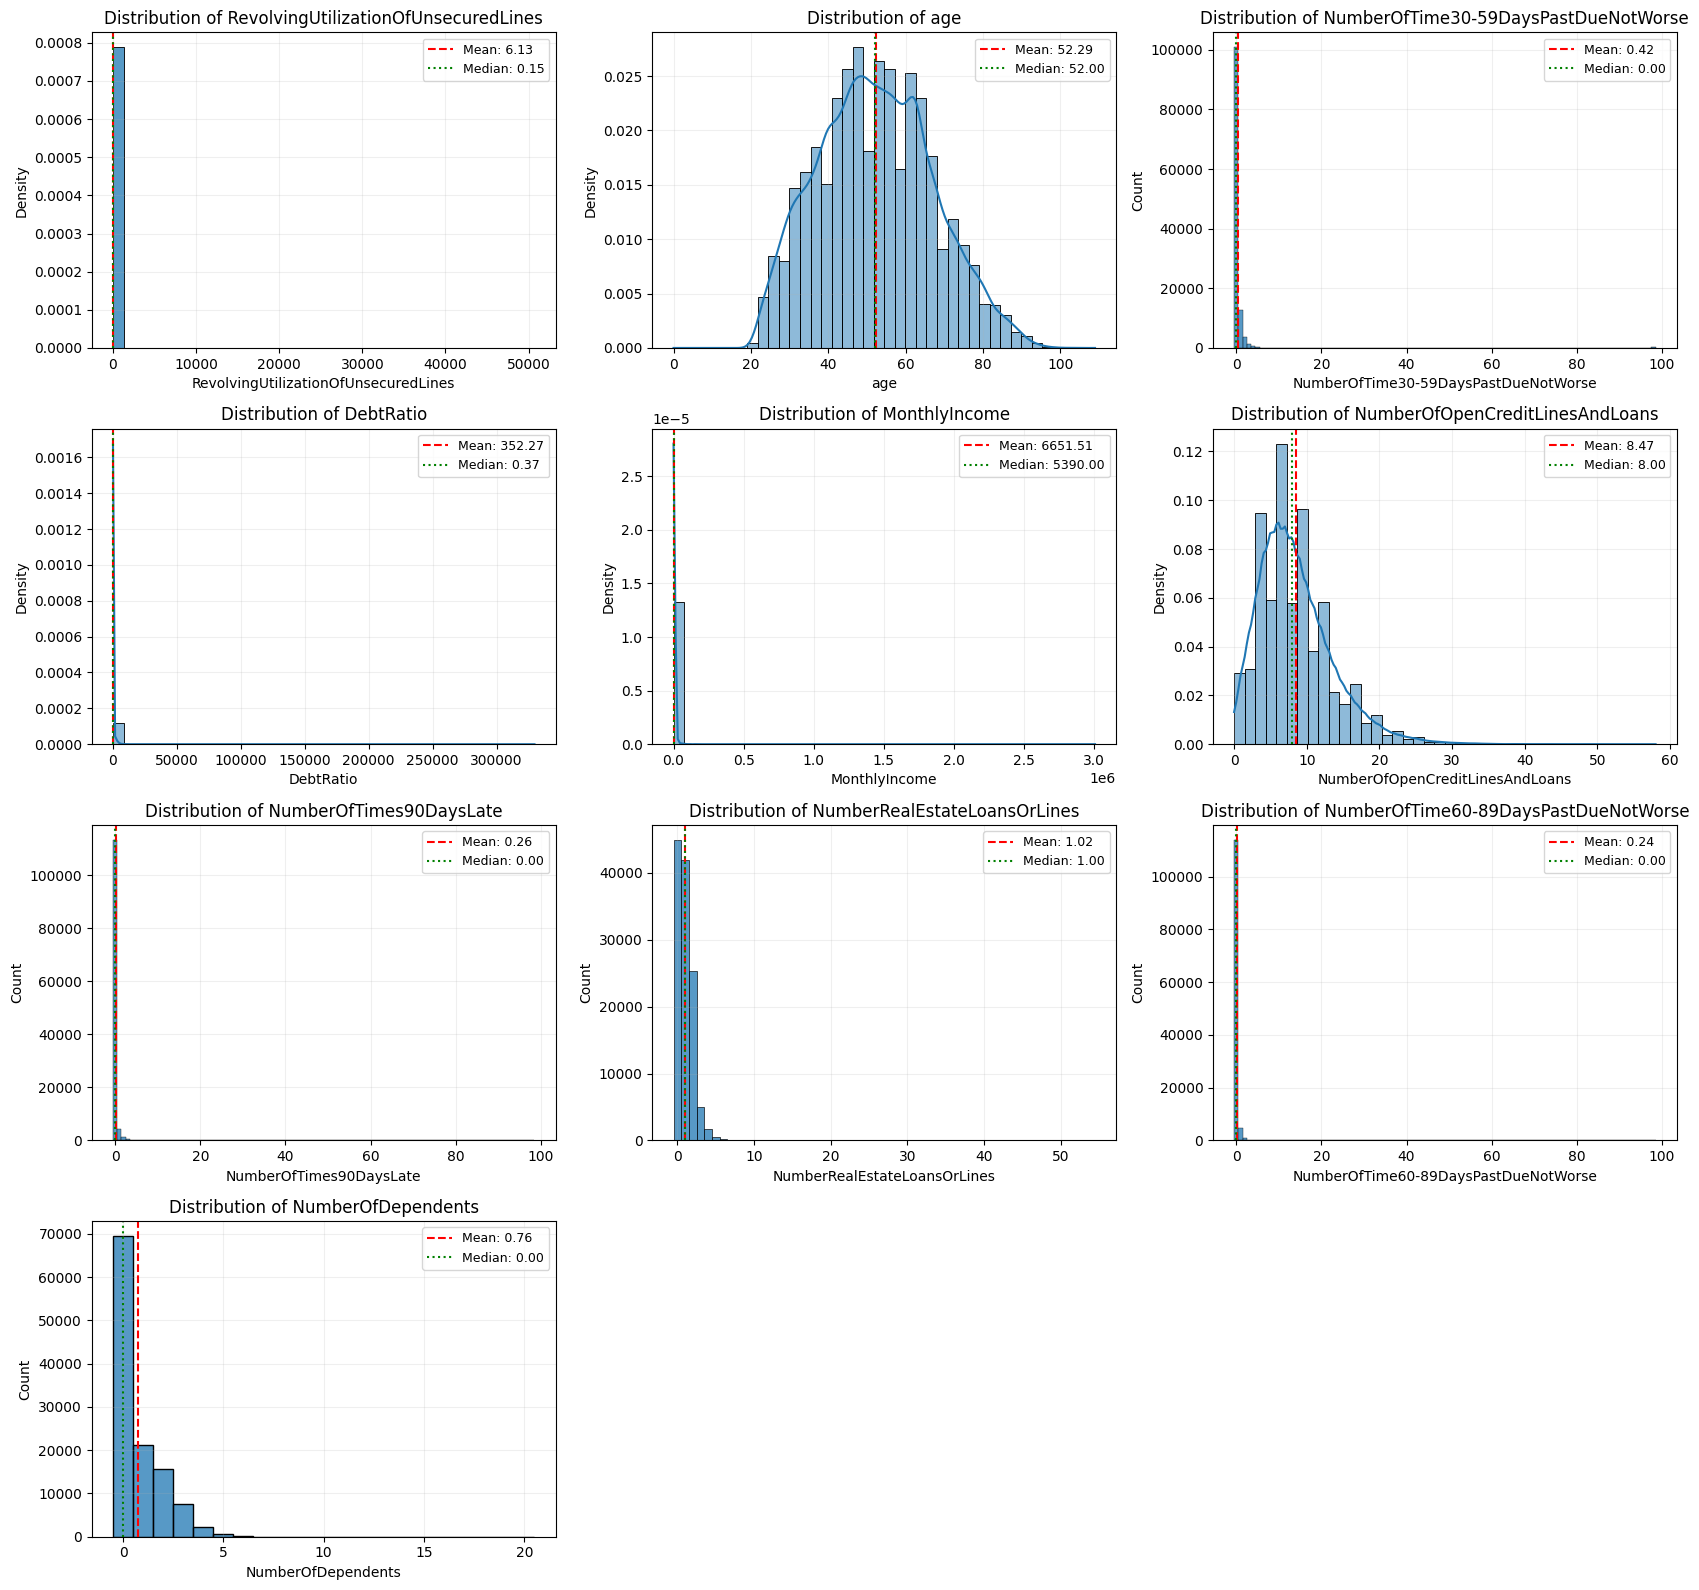

In [20]:
def plot_numerical_distributions(data, cols, ncols=3, bins=40):

    nrows = math.ceil(len(cols) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(17, nrows * 4))
    axes = np.array(axes).reshape(-1)

    for ax, col in zip(axes, cols):

        s = data[col].dropna()
        discrete = is_discrete(s)

        plot_kwargs = {
            "x": s,
            "ax": ax,
            "kde": not discrete and s.eq(0).mean() < 0.05,
            "stat": "count" if discrete else "density",
        }

        if discrete:
            plot_kwargs["discrete"] = True
        else:
            plot_kwargs["bins"] = bins

        sns.histplot(**plot_kwargs)

        ax.axvline(s.mean(), color="red", linestyle="--", linewidth=1.5,
                   label=f"Mean: {s.mean():.2f}")
        ax.axvline(s.median(), color="green", linestyle=":", linewidth=1.5,
                   label=f"Median: {s.median():.2f}")

        ax.set_title(f"Distribution of {col}")
        ax.set_ylabel("Count" if discrete else "Density")
        ax.legend(fontsize=9)
        ax.grid(alpha=0.2)

    for ax in axes[len(cols):]:
        ax.remove()

    plt.tight_layout()
    plt.show()


if numeric_cols:
    plot_numerical_distributions(X_eda, numeric_cols)

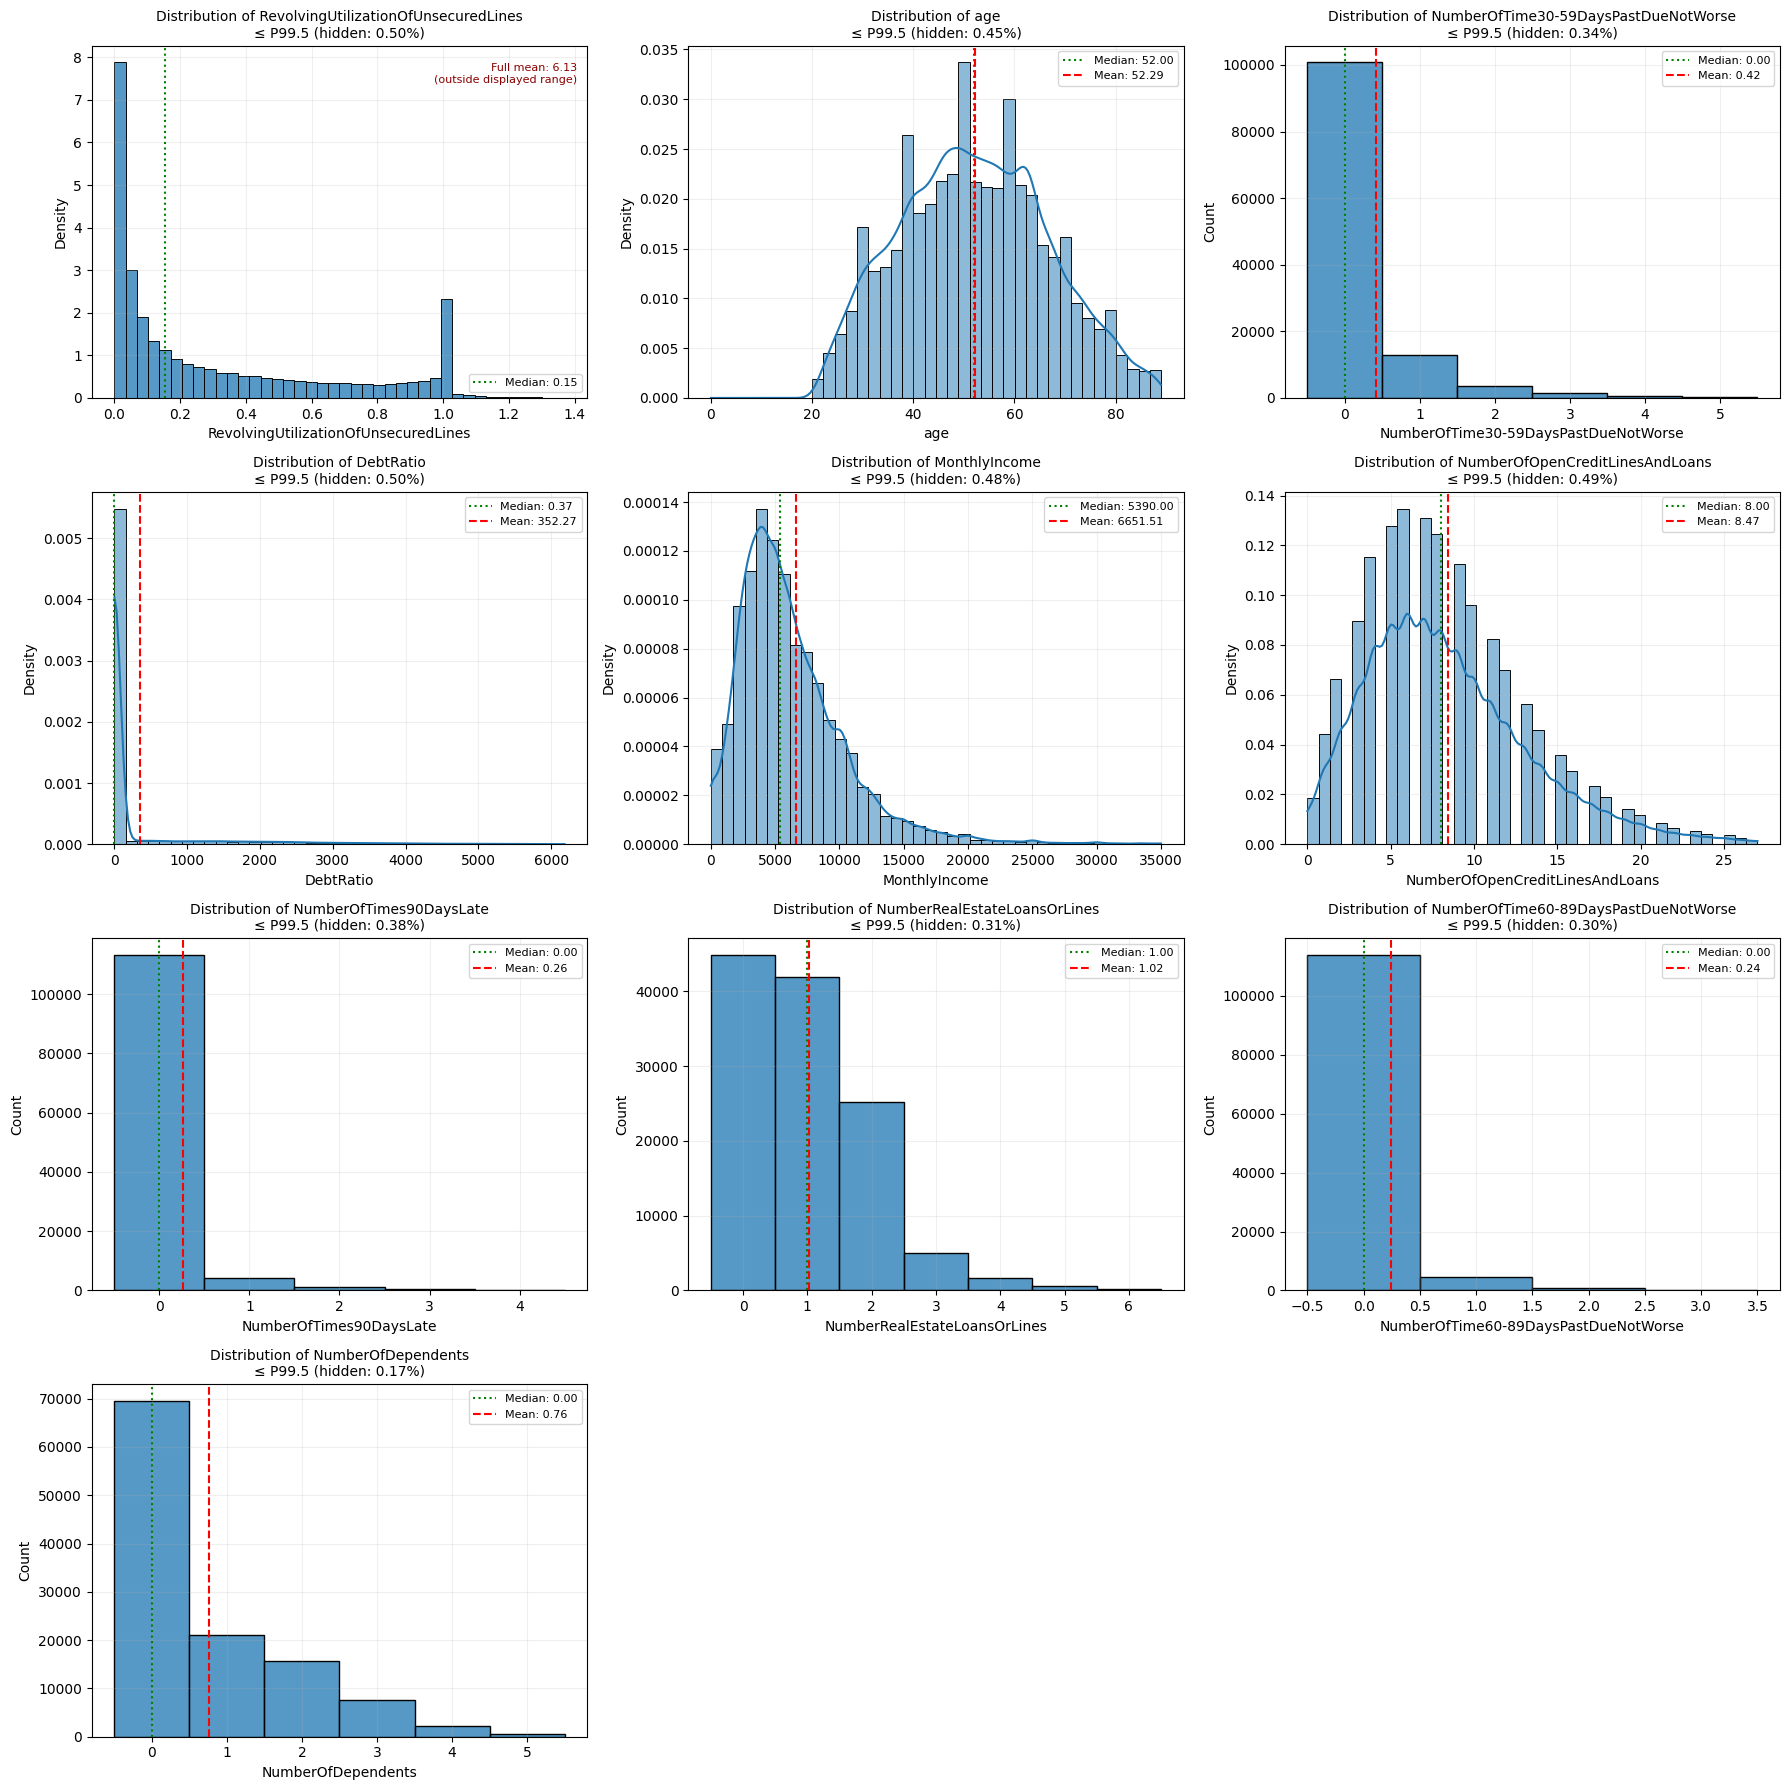

In [22]:

def plot_numerical_distributions_updated(
    data, cols, ncols=3, bins=40, upper_quantile=0.995
):
    nrows = math.ceil(len(cols) / ncols)
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(18, nrows * 4.5)
    )
    axes = np.asarray(axes).reshape(-1)

    for ax, col in zip(axes, cols):

        s = data[col].replace(
            [np.inf, -np.inf], np.nan
        ).dropna()

        if s.empty:
            ax.set_visible(False)
            continue

        # Original statistics
        original_mean = s.mean()
        original_median = s.median()

        # Visualization-only upper bound
        upper = s.quantile(upper_quantile)
        s_plot = s[s <= upper]

        hidden_pct = (1 - len(s_plot) / len(s)) * 100

        discrete = is_discrete(s)

        plot_kwargs = {
            "x": s_plot,
            "ax": ax,
            "stat": "count" if discrete else "density",
            "kde": (
                not discrete
                and s_plot.eq(0).mean() < 0.05
            ),
        }

        if discrete:
            plot_kwargs["discrete"] = True
        else:
            plot_kwargs["bins"] = bins

        sns.histplot(**plot_kwargs)

        # Original median
        ax.axvline(
            original_median,
            color="green",
            linestyle=":",
            linewidth=1.5,
            label=f"Median: {original_median:.2f}"
        )

        # Original mean, if visible
        if original_mean <= upper:
            ax.axvline(
                original_mean,
                color="red",
                linestyle="--",
                linewidth=1.5,
                label=f"Mean: {original_mean:.2f}"
            )
        else:
            ax.text(
                0.98, 0.95,
                f"Full mean: {original_mean:.2f}\n"
                "(outside displayed range)",
                transform=ax.transAxes,
                ha="right",
                va="top",
                fontsize=8,
                color="darkred"
            )

        ax.set_title(
            f"Distribution of {col}\n"
            f"≤ P{upper_quantile * 100:g} "
            f"(hidden: {hidden_pct:.2f}%)",
            fontsize=10
        )

        ax.set_ylabel("Count" if discrete else "Density")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.2)

    for ax in axes[len(cols):]:
        ax.remove()

    plt.tight_layout()
    plt.show()


if numeric_cols:
    plot_numerical_distributions_updated(
        X_eda,
        numeric_cols,
        upper_quantile=0.995
    )


## 4.4 Distribution Diagnostics

### 4.4.1 Normal Q-Q Plots

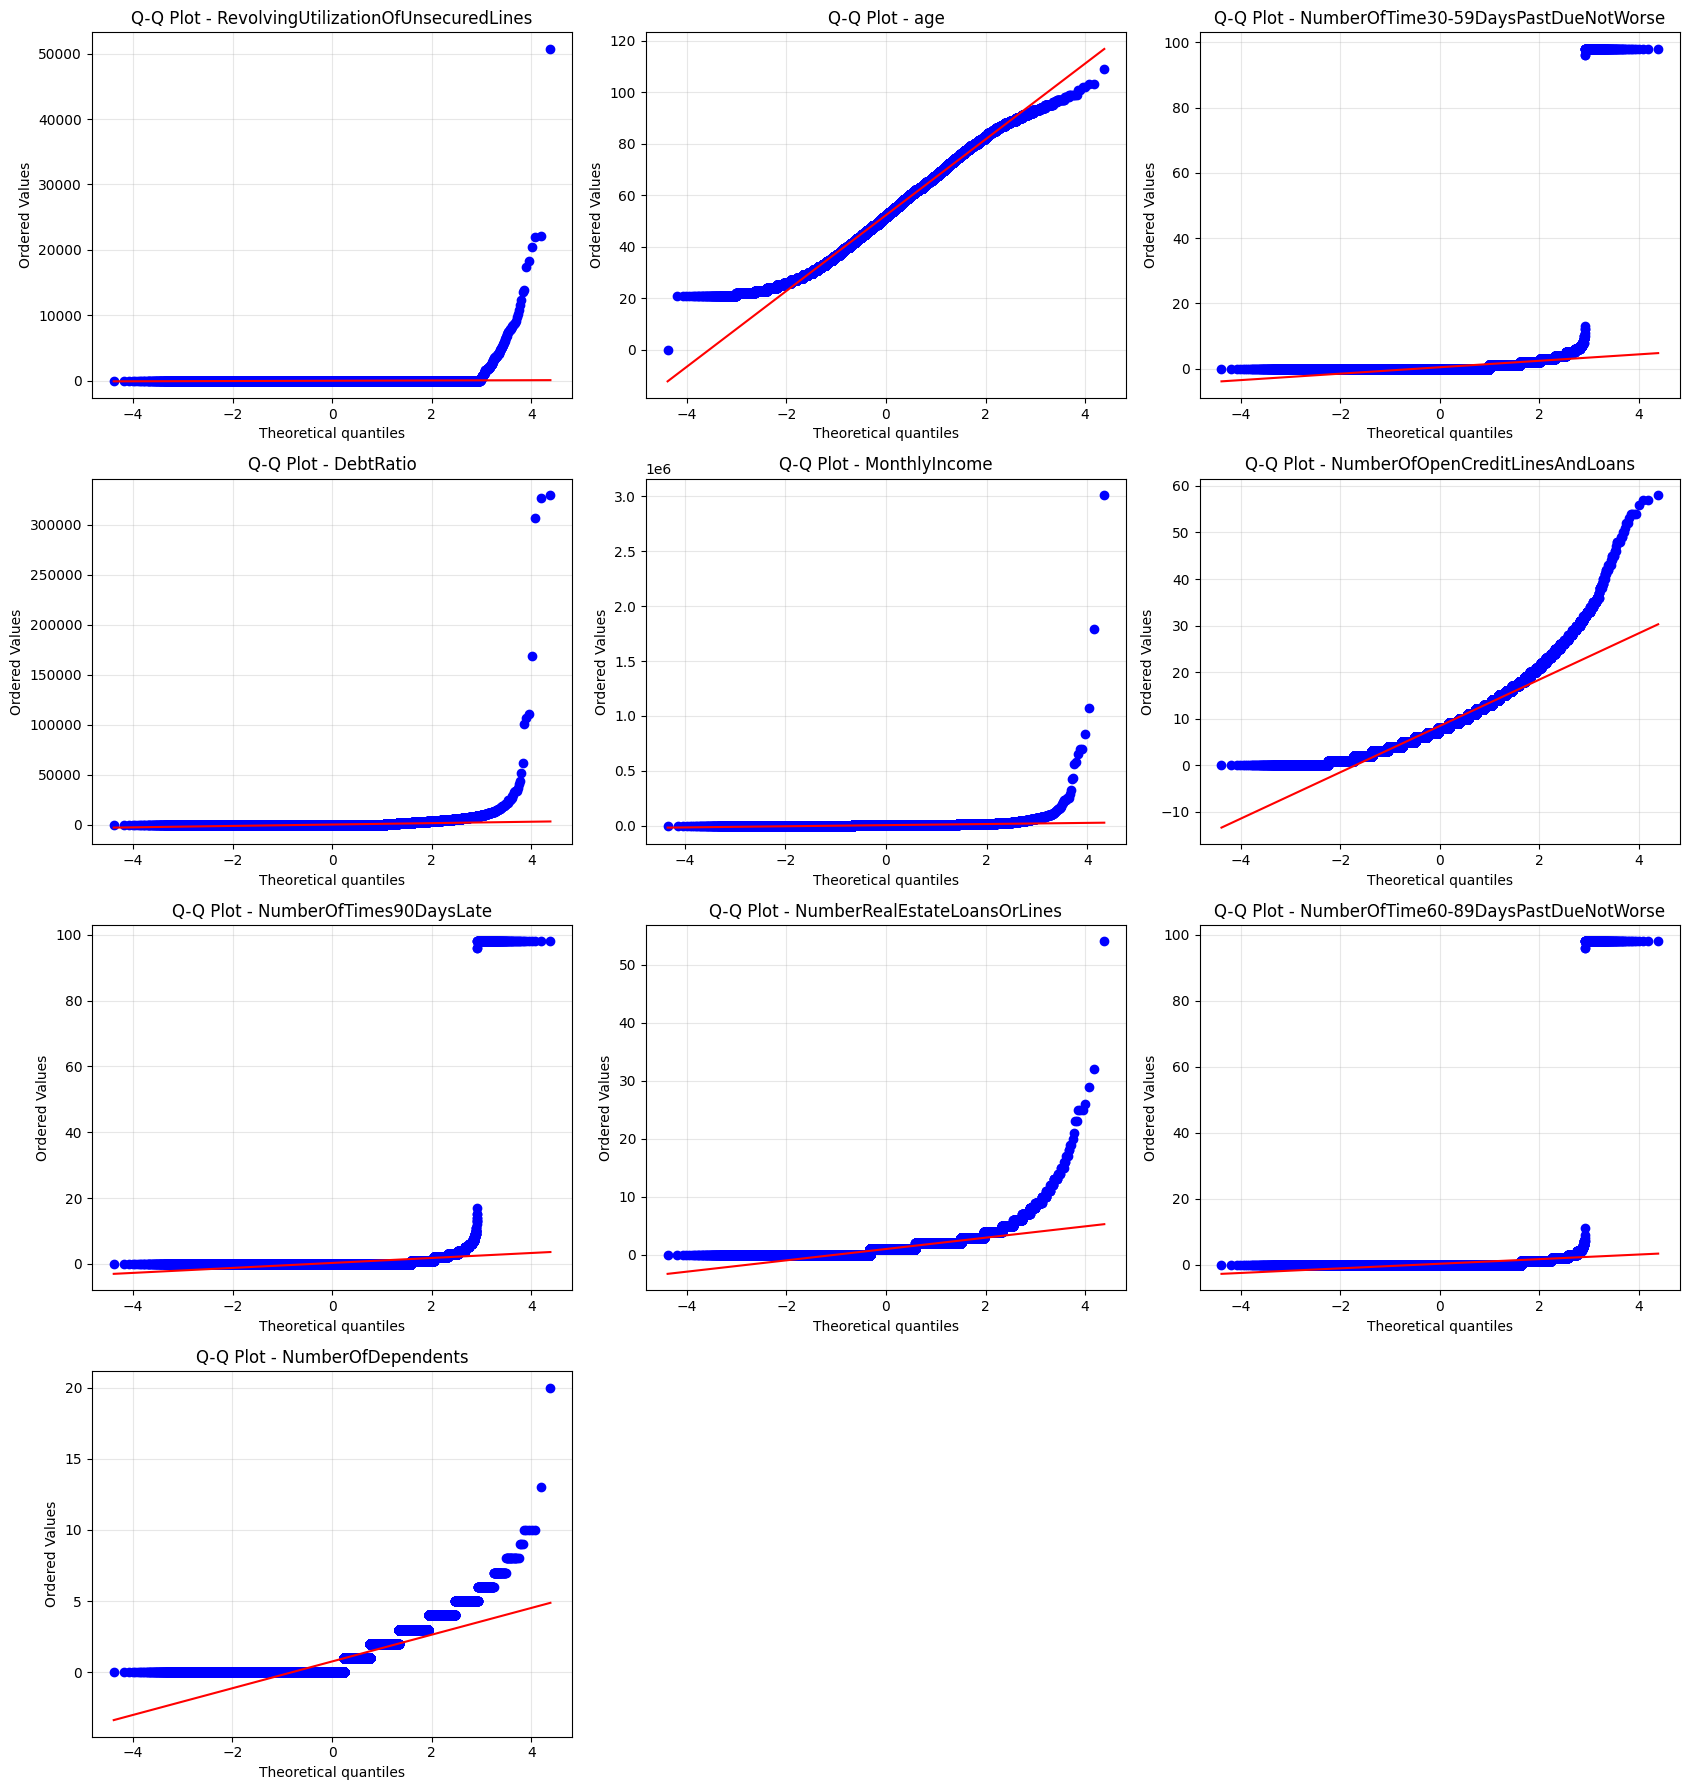

In [21]:
def draw_qq_plots(data, cols, ncols=3):

    nrows = math.ceil(len(cols) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(17, 4.5 * nrows))
    axes = np.asarray(axes).ravel()

    for ax, col in zip(axes, cols):
        stats.probplot(data[col].dropna(), dist="norm", plot=ax)
        ax.set_title(f"Q-Q Plot - {col}")
        ax.grid(alpha=0.3)

    for ax in axes[len(cols):]:
        ax.remove()

    plt.tight_layout()
    plt.show()


if numeric_cols:
    draw_qq_plots(X_eda, numeric_cols)

### 4.4.2 Probability Distribution Fitting (AIC / BIC)

/usr/local/lib/python3.13/dist-packages/scipy/stats/_continuous_distns.py:2750: RuntimeWarning: divide by zero encountered in power
  return c*pow(x, c-1)*np.exp(-pow(x, c))


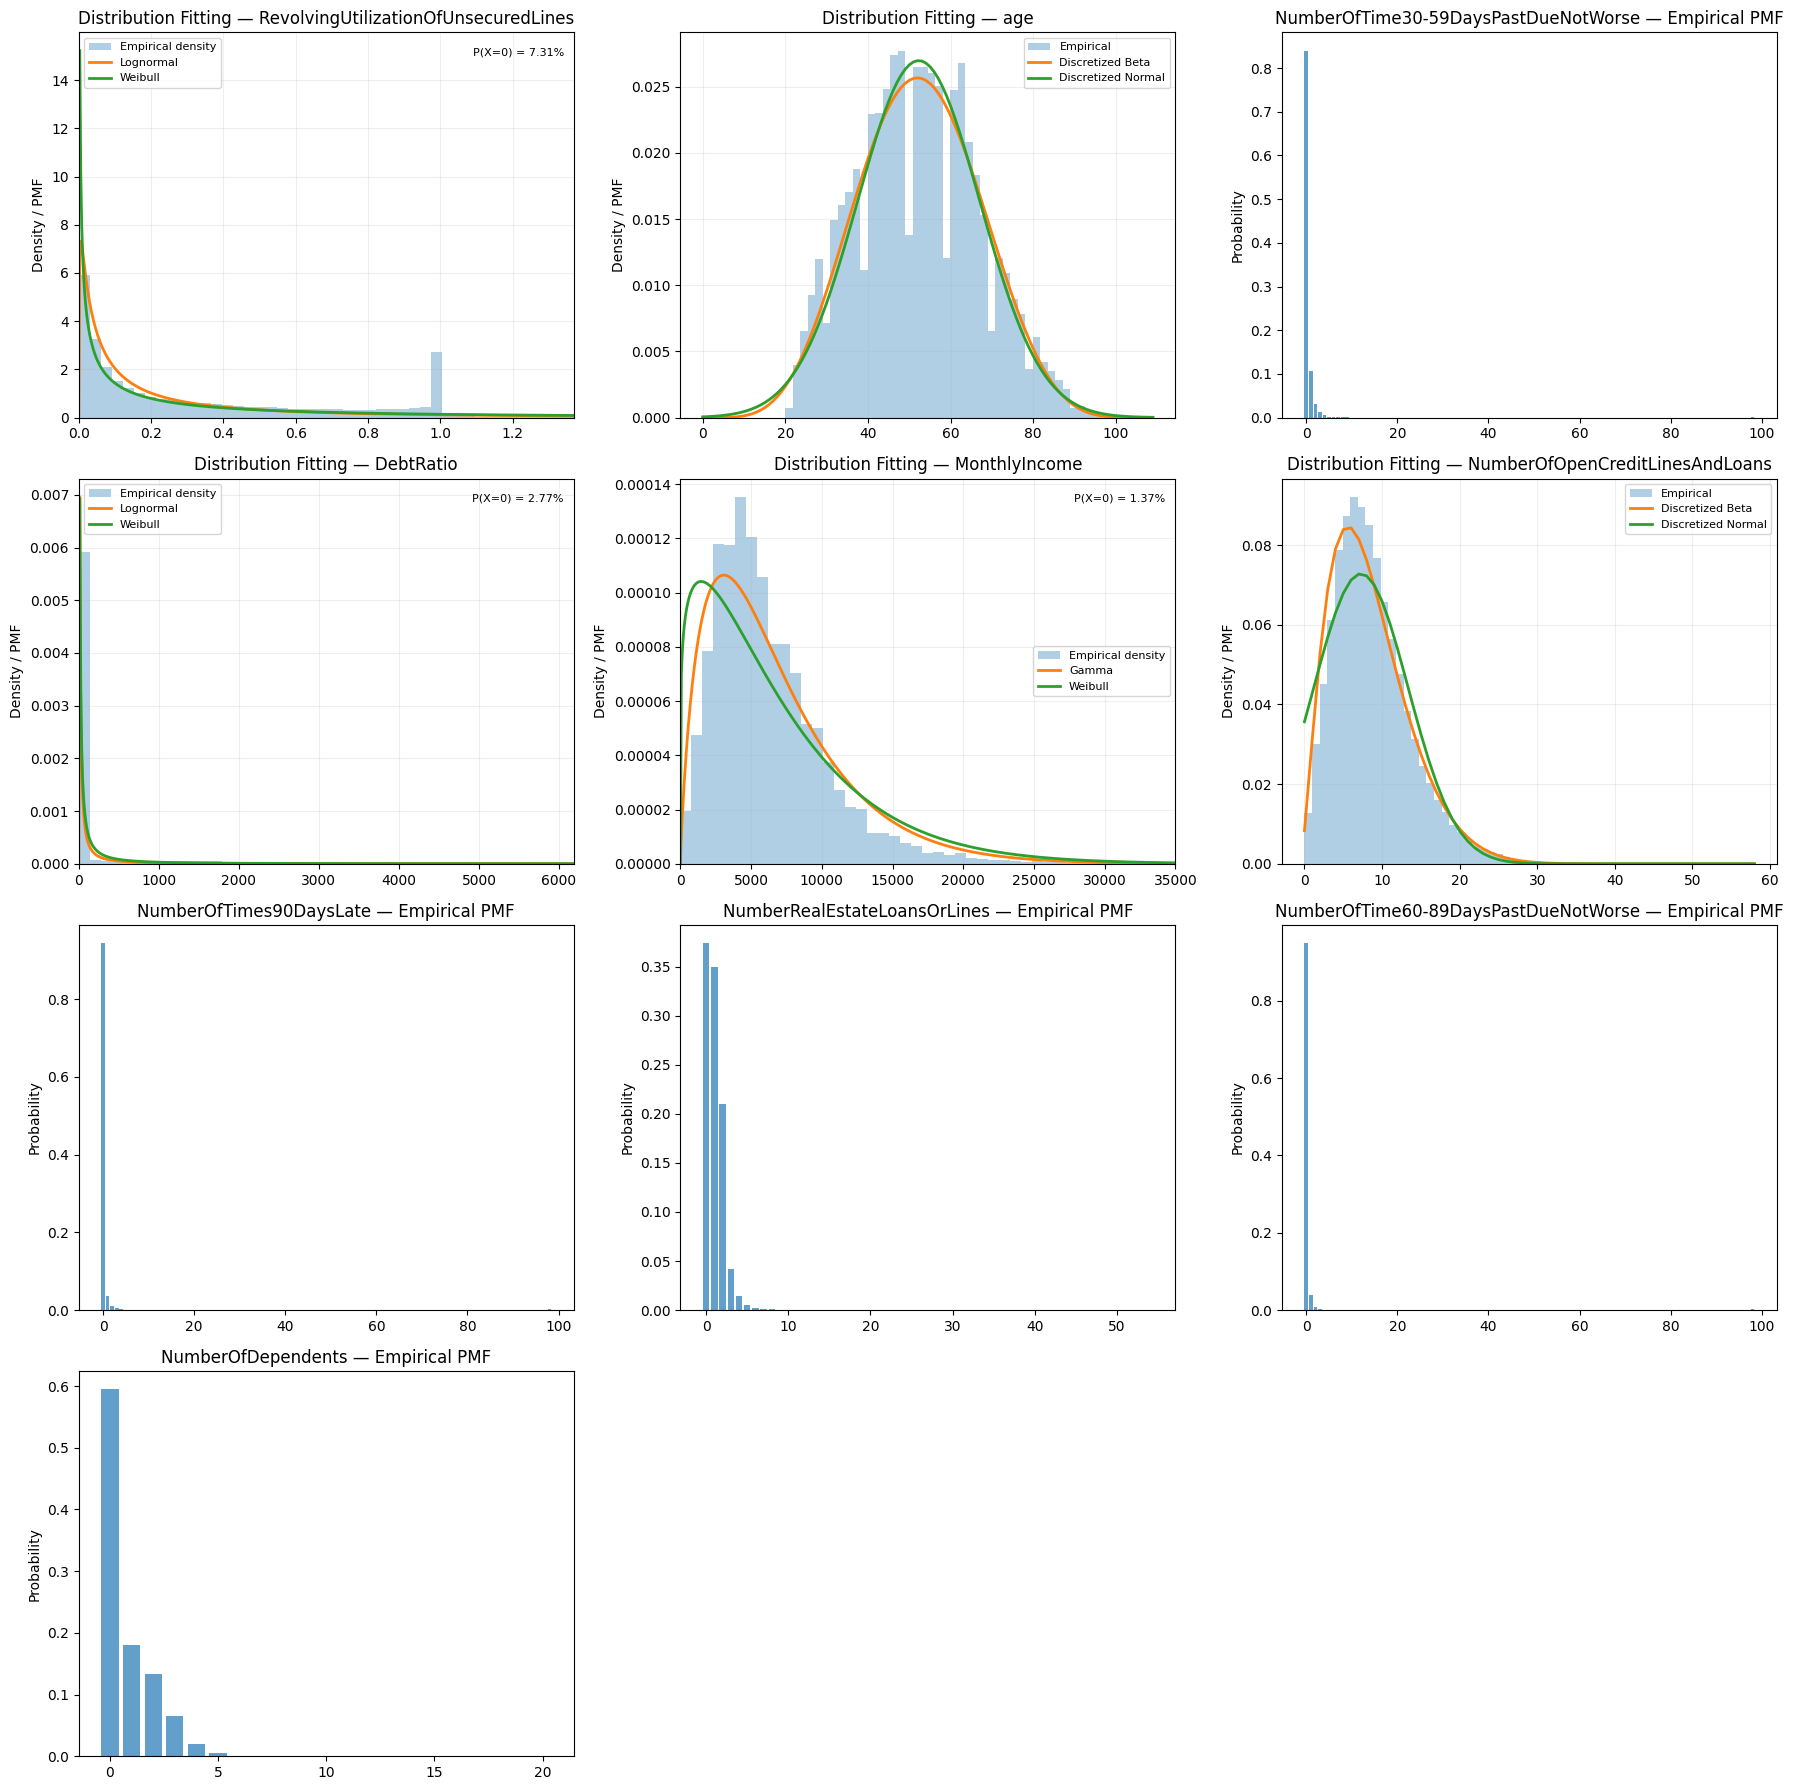

Best Fitted Distributions (by AIC)


,Feature,Distribution,AIC,BIC
0,DebtRatio,Lognormal,682068.62,682097.71
1,MonthlyIncome,Gamma,1861606.02,1861634.45
2,NumberOfOpenCreditLinesAndLoans,Discretized Beta,715452.21,715471.60
3,RevolvingUtilizationOfUnsecuredLines,Lognormal,67169.75,67198.84
4,age,Discretized Beta,984517.36,984536.75


In [23]:
def fit_continuous_distributions(x):

    x = np.asarray(x, dtype=float)
    has_negative = np.any(x < 0)
    has_zeros = np.any(x == 0)

    if has_negative:
        candidates = {
            "Normal": (stats.norm, {}),
            "Logistic": (stats.logistic, {}),
            "Laplace": (stats.laplace, {}),
            "Uniform": (stats.uniform, {}),
        }
        fit_data = x
    else:
        candidates = {
            "Gamma": (stats.gamma, {"floc": 0}),
            "Lognormal": (stats.lognorm, {"floc": 0}),
            "Weibull": (stats.weibull_min, {"floc": 0}),
            "Exponential": (stats.expon, {"floc": 0}),
        }
        if not has_zeros:
            candidates["Normal"] = (stats.norm, {})
        candidates["Uniform"] = (stats.uniform, {})
        fit_data = x[x > 0]

    fitted = {}
    n = len(x)
    n_zero = np.sum(x == 0)
    p_zero = n_zero / n

    for name, (dist, fixed_params) in candidates.items():
        try:
            params = dist.fit(fit_data, **fixed_params)
            logpdf = dist.logpdf(fit_data, *params)

            if not np.all(np.isfinite(logpdf)):
                continue

            log_likelihood = np.sum(logpdf)
            k = len(params) - len(fixed_params)

            # Two-part model for zero-inclusive variables
            if has_zeros and not has_negative:
                log_likelihood += n_zero * np.log(p_zero) + len(fit_data) * np.log1p(-p_zero)
                k += 1

            fitted[name] = {
                "aic": 2 * k - 2 * log_likelihood,
                "bic": k * np.log(n) - 2 * log_likelihood,
                "dist": dist,
                "params": params,
                "p_zero": p_zero if has_zeros else 0,
            }
        except (ValueError, RuntimeError, FloatingPointError):
            continue

    return fitted


def fit_bounded_discrete(x, lower, upper):

    values = np.arange(lower, upper + 1)
    counts = np.bincount(x.astype(int) - lower, minlength=len(values))
    K, n = len(values), len(x)

    def log_likelihood(probs):
        return np.sum(counts * np.log(np.clip(probs, 1e-300, 1)))

    def beta_probs(a, b):
        return np.diff(stats.beta.cdf(np.linspace(0, 1, K + 1), a, b))

    def normal_probs(mu, sigma):
        probs = stats.norm.cdf(values + 0.5, mu, sigma) - stats.norm.cdf(values - 0.5, mu, sigma)
        return probs / probs.sum()

    beta_fit = minimize(lambda z: -log_likelihood(beta_probs(np.exp(z[0]), np.exp(z[1]))),
                        x0=[0, 0], bounds=[(-4, 4), (-4, 4)], method="L-BFGS-B")

    normal_fit = minimize(lambda z: -log_likelihood(normal_probs(z[0], np.exp(z[1]))),
                          x0=[np.mean(x), np.log(max(np.std(x), 1))],
                          bounds=[(lower - K, upper + K), (np.log(0.3), np.log(3 * K))],
                          method="L-BFGS-B")

    models = {"Discrete Uniform": (np.ones(K) / K, 0)}
    if beta_fit.success:
        models["Discretized Beta"] = (beta_probs(*np.exp(beta_fit.x)), 2)
    if normal_fit.success:
        models["Discretized Normal"] = (normal_probs(normal_fit.x[0], np.exp(normal_fit.x[1])), 2)

    fitted = {}
    for name, (probs, k) in models.items():
        ll = log_likelihood(probs)
        fitted[name] = {"aic": 2 * k - 2 * ll, "bic": k * np.log(n) - 2 * ll,
                        "values": values, "pmf": probs}

    return fitted


def analyze_numerical_distributions(data, cols, ncols=3, bins=45, upper_quantile=0.995):

    empirical_discrete = {c for c in cols if is_discrete(data[c])}
    bounded_discrete = {
        c: (int(data[c].min()), int(data[c].max()))
        for c in cols
        if c not in empirical_discrete
        and is_integer_valued(data[c])
        and data[c].max() - data[c].min() <= 1000
    }

    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4.5 * nrows))
    axes = np.asarray(axes).ravel()

    results = []

    for ax, col in zip(axes, cols):

        x = data[col].dropna().to_numpy(dtype=float)
        x = x[np.isfinite(x)]

        if col in empirical_discrete:
            values, counts = np.unique(x, return_counts=True)
            ax.bar(values, counts / len(x), alpha=0.7)
            ax.set_title(f"{col} — Empirical PMF")
            ax.set_ylabel("Probability")
            continue

        if col in bounded_discrete:
            lower, upper = bounded_discrete[col]
            fitted = fit_bounded_discrete(x, lower, upper)
            ax.hist(x, bins=min(60, upper - lower + 1), density=True, alpha=0.35, label="Empirical")
            for name, model in sorted(fitted.items(), key=lambda item: item[1]["aic"])[:2]:
                ax.plot(model["values"], model["pmf"], linewidth=2, label=name)

        else:
            fitted = fit_continuous_distributions(x)
            low = np.quantile(x, 0.005) if np.any(x < 0) else min(0, np.min(x))
            high = np.quantile(x, upper_quantile)
            if high <= low:
                high = np.max(x)

            edges = np.linspace(low, high, bins + 1)
            bin_width = edges[1] - edges[0]
            zero_mass = np.any(x == 0) and not np.any(x < 0)
            histogram_data = x[x != 0] if zero_mass else x

            ax.hist(histogram_data, bins=edges,
                    weights=np.full(len(histogram_data), 1 / (len(x) * bin_width)),
                    alpha=0.35, label="Empirical density")

            x_grid = np.linspace(low, high, 500)
            for name, model in sorted(fitted.items(), key=lambda item: item[1]["aic"])[:2]:
                density = model["dist"].pdf(x_grid, *model["params"]) * (1 - model["p_zero"])
                ax.plot(x_grid, density, linewidth=2, label=name)

            if zero_mass:
                ax.text(0.98, 0.96, f"P(X=0) = {np.mean(x == 0):.2%}", transform=ax.transAxes,
                        ha="right", va="top", fontsize=8)
            ax.set_xlim(low, high)

        for name, model in fitted.items():
            results.append({"Feature": col, "Distribution": name,
                            "AIC": model["aic"], "BIC": model["bic"]})

        ax.set_title(f"Distribution Fitting — {col}")
        ax.set_ylabel("Density / PMF")
        ax.grid(alpha=0.2)
        ax.legend(fontsize=8)

    for ax in axes[len(cols):]:
        ax.remove()

    plt.tight_layout()
    plt.show()

    results_df = pd.DataFrame(results, columns=["Feature", "Distribution", "AIC", "BIC"])
    best_models = (
        results_df.loc[results_df.groupby("Feature")["AIC"].idxmin()]
        .sort_values("Feature")
        .reset_index(drop=True)
        if not results_df.empty else results_df
    )

    return results_df, best_models


if numeric_cols:
    all_fits, best_fits = analyze_numerical_distributions(X_eda, numeric_cols)
    print("Best Fitted Distributions (by AIC)")
    display(best_fits.round(2))

### 4.4.3 Goodness of Fit (Kolmogorov–Smirnov Distance)

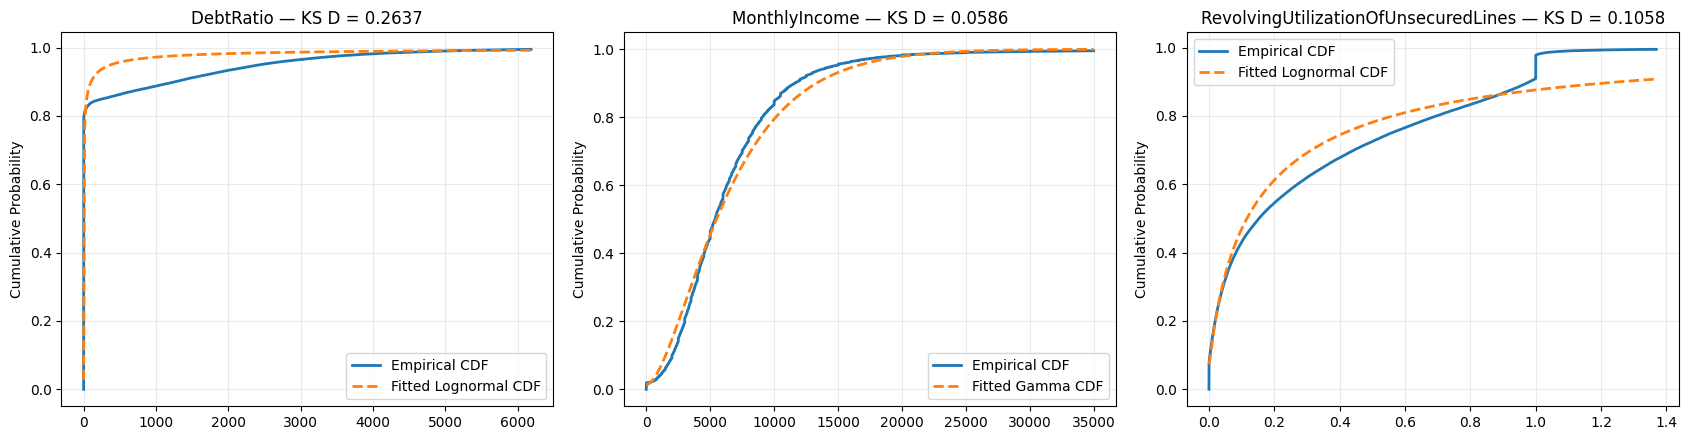

,Feature,Distribution,N,KS_D,Zero_Rate
0,DebtRatio,Lognormal,120000,0.2637,0.0277
1,RevolvingUtilizationOfUnsecuredLines,Lognormal,120000,0.1058,0.0730
2,MonthlyIncome,Gamma,96325,0.0586,0.0137


In [24]:
CONTINUOUS_DISTRIBUTIONS = {
    "Gamma": stats.gamma,
    "Lognormal": stats.lognorm,
    "Weibull": stats.weibull_min,
    "Exponential": stats.expon,
    "Normal": stats.norm,
    "Logistic": stats.logistic,
    "Laplace": stats.laplace,
    "Uniform": stats.uniform,
}
ZERO_LOCATION = {"Gamma", "Lognormal", "Weibull", "Exponential"}


def goodness_of_fit_analysis(data, distribution_map, ncols=3):

    results = []
    nrows = int(np.ceil(len(distribution_map) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(17, 4.5 * nrows))
    axes = np.asarray(axes).ravel()

    for ax, (col, (name, dist)) in zip(axes, distribution_map.items()):

        x = data[col].dropna().to_numpy(dtype=float)
        x = x[np.isfinite(x)]

        has_zero_mass = np.all(x >= 0) and np.any(x == 0)
        positive_data = x[x > 0] if has_zero_mass else x
        params = dist.fit(positive_data, floc=0) if name in ZERO_LOCATION else dist.fit(positive_data)
        p_zero = np.mean(x == 0) if has_zero_mass else 0.0

        def fitted_cdf(values):
            values = np.asarray(values)
            cdf = dist.cdf(values, *params)
            if has_zero_mass:
                cdf = np.where(values < 0, 0.0, p_zero + (1 - p_zero) * cdf)
            return cdf

        x_sorted = np.sort(x)
        n = len(x_sorted)
        empirical_cdf = np.arange(1, n + 1) / n

        # KS distance including discrete probability masses (left and right limits)
        unique_values, counts = np.unique(x_sorted, return_counts=True)
        cumulative = np.cumsum(counts)
        ks_d = max(
            np.max(np.abs(cumulative / n - fitted_cdf(unique_values))),
            np.max(np.abs((cumulative - counts) / n - fitted_cdf(np.nextafter(unique_values, -np.inf)))),
        )

        results.append({"Feature": col, "Distribution": name, "N": n,
                        "KS_D": ks_d, "Zero_Rate": p_zero})

        lower, upper = np.quantile(x, [0.005, 0.995])
        mask = (x_sorted >= lower) & (x_sorted <= upper)
        x_grid = np.linspace(lower, upper, 500)

        ax.plot(x_sorted[mask], empirical_cdf[mask], label="Empirical CDF", linewidth=2)
        ax.plot(x_grid, fitted_cdf(x_grid), linestyle="--", linewidth=2, label=f"Fitted {name} CDF")
        ax.set_title(f"{col} — KS D = {ks_d:.4f}")
        ax.set_ylabel("Cumulative Probability")
        ax.legend()
        ax.grid(alpha=0.25)

    for ax in axes[len(distribution_map):]:
        ax.remove()

    plt.tight_layout()
    plt.show()

    return pd.DataFrame(results).sort_values("KS_D", ascending=False).reset_index(drop=True)


best_distributions = (
    {
        row.Feature: (row.Distribution, CONTINUOUS_DISTRIBUTIONS[row.Distribution])
        for row in best_fits.itertuples()
        if row.Distribution in CONTINUOUS_DISTRIBUTIONS
    }
    if numeric_cols else {}
)

if best_distributions:
    display(goodness_of_fit_analysis(X_eda, best_distributions).round(4))
else:
    print("No continuous distribution fits to evaluate.")

## 4.5 Boxplots & Violin Plots

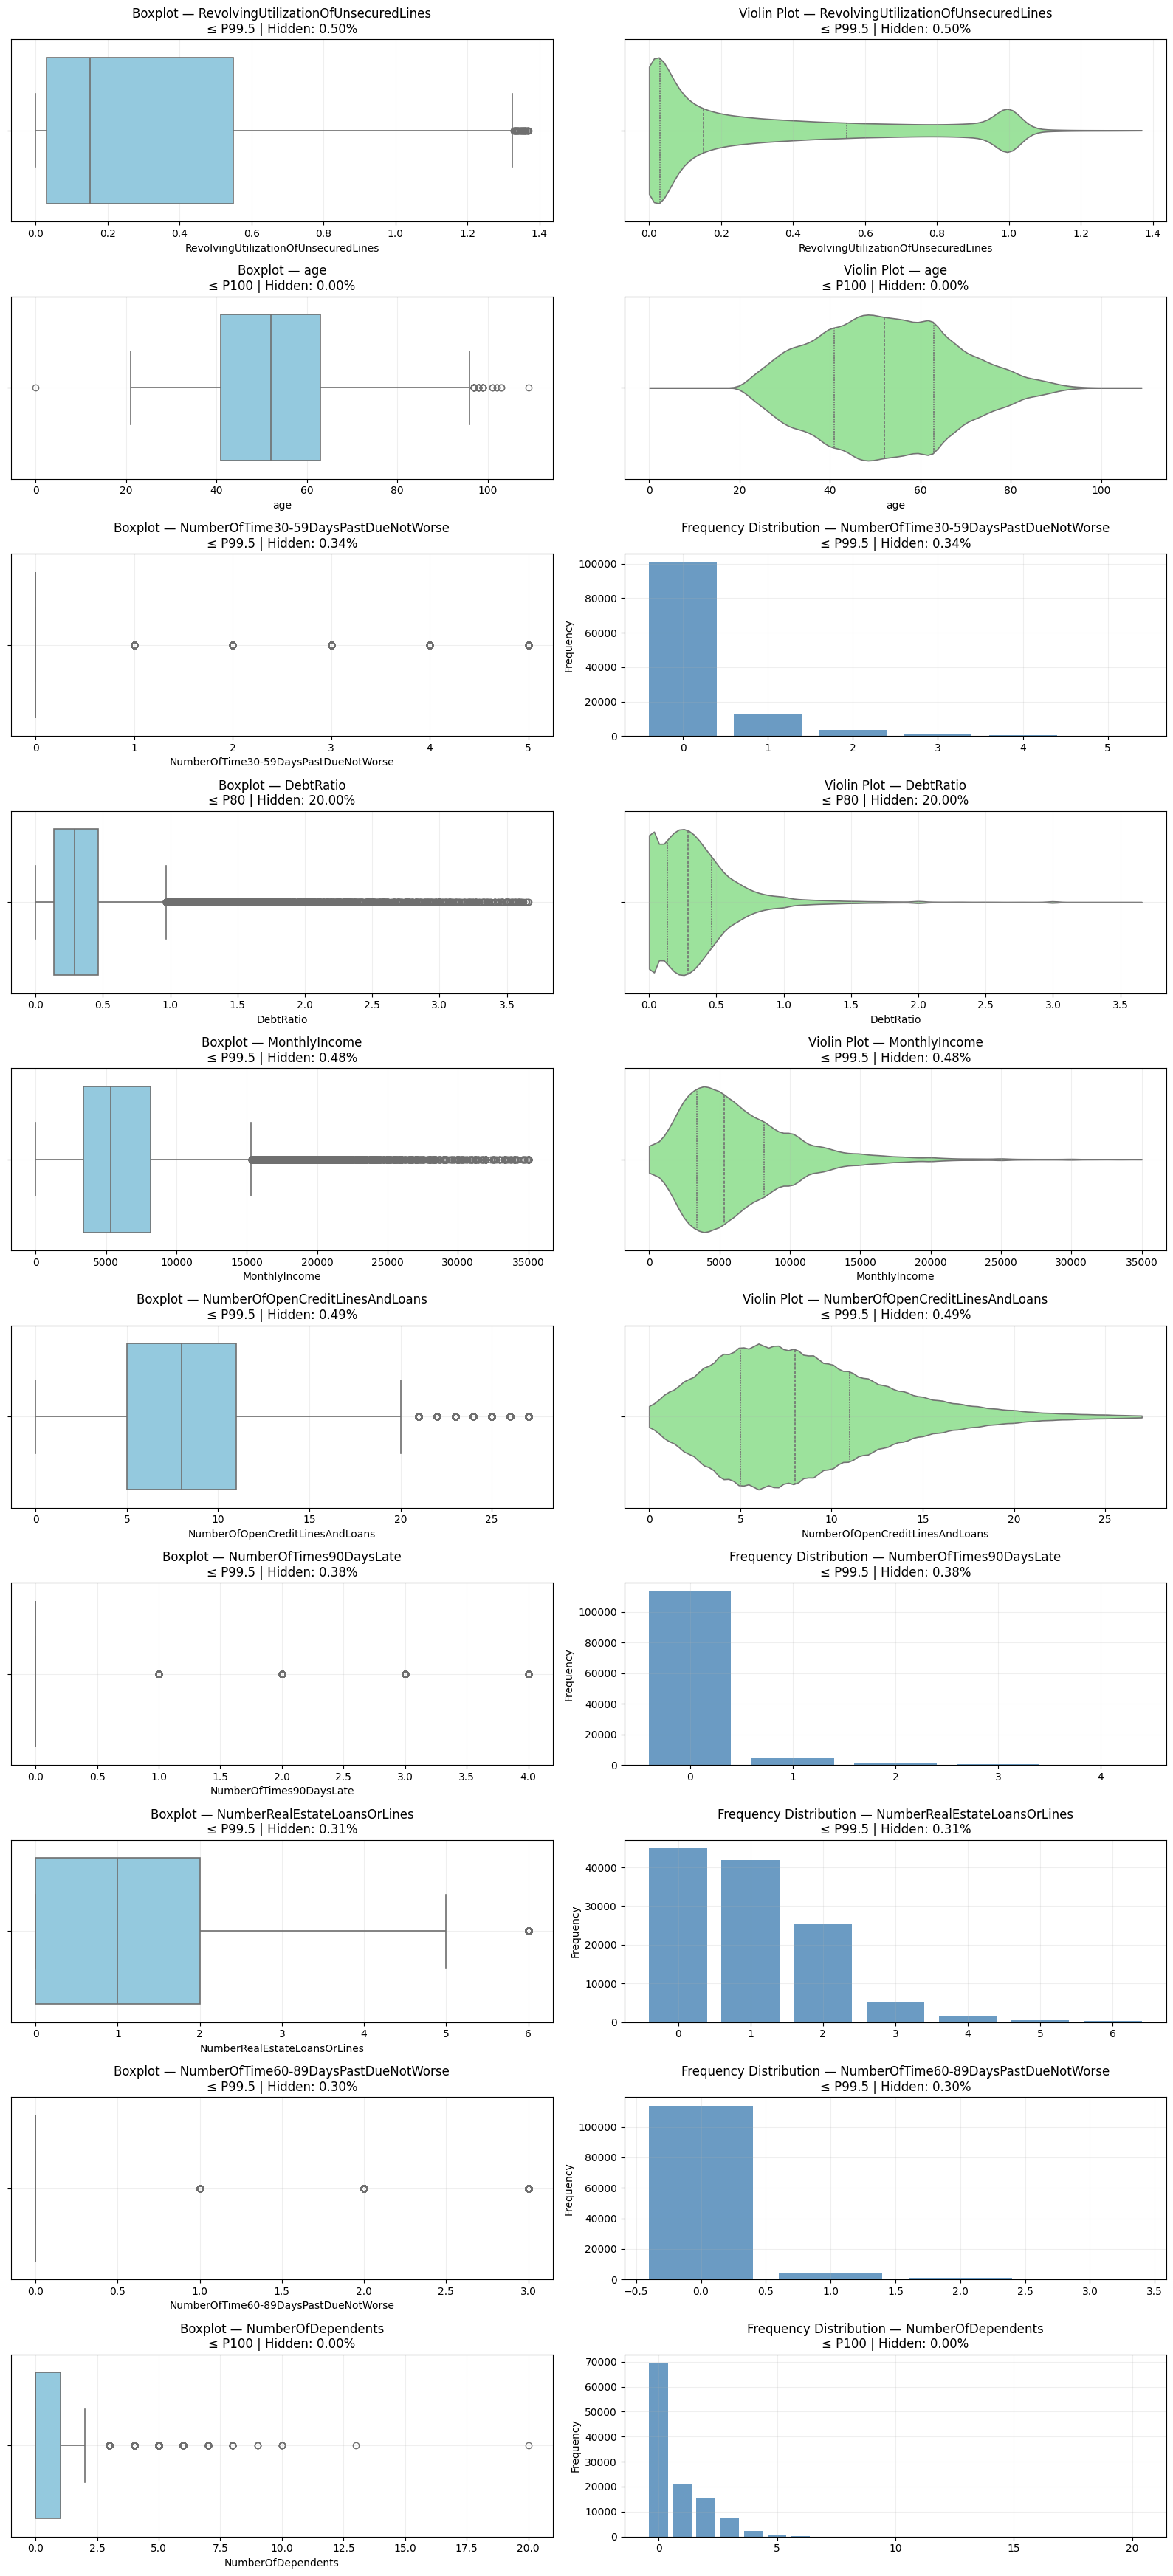

In [27]:
def plot_box_violin(data, cols, upper_quantile=0.995):

    # Feature-specific visualization limits
    zoom_quantiles = {
        "DebtRatio": 0.80,
        "age": 1.00,
        "NumberOfDependents": 1.00,
    }

    fig, axes = plt.subplots(
        nrows=len(cols),
        ncols=2,
        figsize=(16, 3.5 * len(cols)),
        squeeze=False
    )

    for i, col in enumerate(cols):

        s = (
            data[col]
            .replace([np.inf, -np.inf], np.nan)
            .dropna()
        )

        ax_box, ax_violin = axes[i]

        if s.empty:
            ax_box.set_visible(False)
            ax_violin.set_visible(False)
            continue

        # Determine visualization-only limit
        q = zoom_quantiles.get(col, upper_quantile)
        upper = s.quantile(q)

        # Do not modify the original dataset
        s_plot = s[s <= upper]

        hidden_pct = (1 - len(s_plot) / len(s)) * 100

        subtitle = (
            f"≤ P{q * 100:g} | "
            f"Hidden: {hidden_pct:.2f}%"
        )

        # Boxplot
        sns.boxplot(
            x=s_plot,
            ax=ax_box,
            color="skyblue",
            showfliers=True,
            linewidth=1.2
        )

        ax_box.set_title(f"Boxplot — {col}\n{subtitle}")
        ax_box.grid(alpha=0.2)

        # Frequency plot for discrete variables
        if is_discrete(s):

            frequencies = s_plot.value_counts().sort_index()

            ax_violin.bar(
                frequencies.index.to_numpy(dtype=float),
                frequencies.values,
                color="steelblue",
                alpha=0.8
            )

            ax_violin.set_title(
                f"Frequency Distribution — {col}\n{subtitle}"
            )
            ax_violin.set_ylabel("Frequency")

        # Violin plot for continuous variables
        else:

            sns.violinplot(
                x=s_plot,
                ax=ax_violin,
                color="lightgreen",
                inner="quart",
                cut=0,
                linewidth=1.2
            )

            ax_violin.set_title(
                f"Violin Plot — {col}\n{subtitle}"
            )

        ax_violin.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()


box_cols = [
    c for c in numeric_cols
    if X_eda[c].nunique(dropna=True) > 2
]

if box_cols:
    plot_box_violin(
        X_eda,
        box_cols,
        upper_quantile=0.995
    )


## 4.6 IQR Outlier Diagnostics

,Feature,Count,Q1,Median,Q3,IQR,Lower_Fence,Upper_Fence,Lower_Outliers,Upper_Outliers,Outlier_Count,Outlier_Rate_%,Extreme_Count,Extreme_Rate_%,P99,Max,Status
0,DebtRatio,120000,0.175,0.366,0.861,0.686,-0.853,1.889,0.0,24938.0,24938.0,20.782,24280.0,20.233,4977.000,329664.0,Applicable
1,NumberOfDependents,116872,0.000,0.000,1.000,1.000,-1.500,2.500,0.0,10660.0,10660.0,9.121,786.0,0.673,4.000,20.0,Applicable
2,MonthlyIncome,96325,3400.000,5390.000,8238.000,4838.000,-3857.000,15495.000,0.0,3971.0,3971.0,4.123,1237.0,1.284,25000.000,3008750.0,Applicable
3,NumberOfOpenCreditLinesAndLoans,120000,5.000,8.000,11.000,6.000,-4.000,20.000,0.0,3195.0,3195.0,2.662,366.0,0.305,25.000,58.0,Applicable
4,NumberRealEstateLoansOrLines,120000,0.000,1.000,2.000,2.000,-3.000,5.000,0.0,626.0,626.0,0.522,162.0,0.135,4.000,54.0,Applicable
5,RevolvingUtilizationOfUnsecuredLines,120000,0.030,0.153,0.558,0.528,-0.763,1.350,0.0,617.0,617.0,0.514,269.0,0.224,1.094,50708.0,Applicable
6,age,120000,41.000,52.000,63.000,22.000,8.000,96.000,1.0,36.0,37.0,0.031,0.0,0.000,87.000,109.0,Applicable
7,NumberOfTime30-59DaysPastDueNotWorse,120000,0.000,0.000,0.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.000,98.0,Zero IQR
8,NumberOfTimes90DaysLate,120000,0.000,0.000,0.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.000,98.0,Zero IQR
9,NumberOfTime60-89DaysPastDueNotWorse,120000,0.000,0.000,0.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000,98.0,Zero IQR


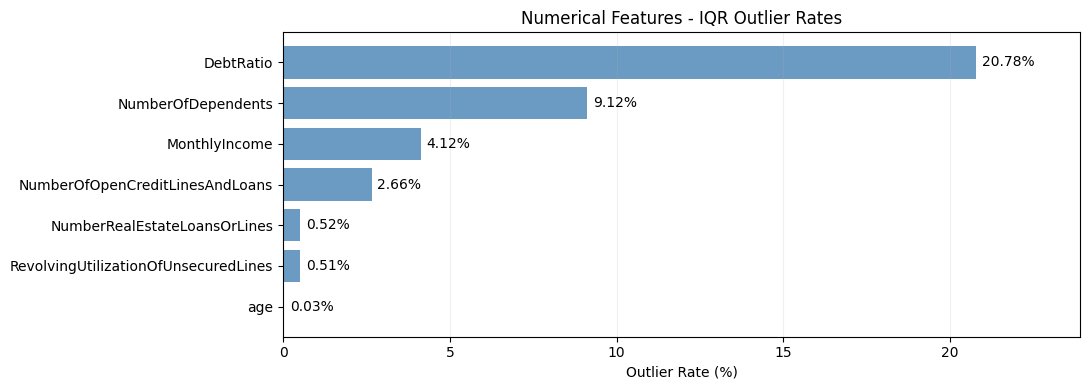

In [26]:
def numerical_boxplot_diagnostics(data, cols):

    results = []

    for col in cols:

        s = data[col].replace([np.inf, -np.inf], np.nan).dropna()

        if s.empty:
            continue

        q1, median, q3 = s.quantile([0.25, 0.50, 0.75])
        iqr = q3 - q1

        if s.nunique() == 1:
            status = "Constant"
        elif iqr == 0:
            status = "Zero IQR"
        else:
            status = "Applicable"

        row = {
            "Feature": col, "Count": len(s), "Q1": q1, "Median": median,
            "Q3": q3, "IQR": iqr, "Lower_Fence": np.nan, "Upper_Fence": np.nan,
            "Lower_Outliers": np.nan, "Upper_Outliers": np.nan,
            "Outlier_Count": np.nan, "Outlier_Rate_%": np.nan,
            "Extreme_Count": np.nan, "Extreme_Rate_%": np.nan,
            "P99": s.quantile(0.99), "Max": s.max(), "Status": status,
        }

        if status == "Applicable":

            lower_fence = q1 - 1.5 * iqr
            upper_fence = q3 + 1.5 * iqr
            lower_count = (s < lower_fence).sum()
            upper_count = (s > upper_fence).sum()
            extreme_mask = (s < q1 - 3 * iqr) | (s > q3 + 3 * iqr)

            row.update({
                "Lower_Fence": lower_fence,
                "Upper_Fence": upper_fence,
                "Lower_Outliers": lower_count,
                "Upper_Outliers": upper_count,
                "Outlier_Count": lower_count + upper_count,
                "Outlier_Rate_%": (lower_count + upper_count) / len(s) * 100,
                "Extreme_Count": extreme_mask.sum(),
                "Extreme_Rate_%": extreme_mask.mean() * 100,
            })

        results.append(row)

    return (
        pd.DataFrame(results)
        .sort_values("Outlier_Rate_%", ascending=False, na_position="last")
        .reset_index(drop=True)
    )


boxplot_summary = numerical_boxplot_diagnostics(X_eda, numeric_cols)
display(boxplot_summary.round(3))

plot_data = boxplot_summary.loc[
    boxplot_summary["Status"] == "Applicable"
].sort_values("Outlier_Rate_%")

if not plot_data.empty:
    fig, ax = plt.subplots(figsize=(11, max(4, 0.5 * len(plot_data))))
    bars = ax.barh(plot_data["Feature"], plot_data["Outlier_Rate_%"],
                   color="steelblue", alpha=0.8)
    ax.bar_label(bars, fmt="%.2f%%", padding=4)
    ax.set_title("Numerical Features - IQR Outlier Rates")
    ax.set_xlabel("Outlier Rate (%)")
    ax.grid(axis="x", alpha=0.2)
    ax.margins(x=0.15)
    plt.tight_layout()
    plt.show()

## 4.7 Outlier Detection Methods Comparison

Method,IQR,Modified Z-Score,Percentile,Z-Score
Feature,,,,
DebtRatio,20.782,21.051,0.999,0.410
MonthlyIncome,4.123,2.848,0.956,0.249
NumberOfOpenCreditLinesAndLoans,2.662,1.305,0.786,1.305
RevolvingUtilizationOfUnsecuredLines,0.514,12.581,1.000,0.126
age,0.031,0.000,1.691,0.031


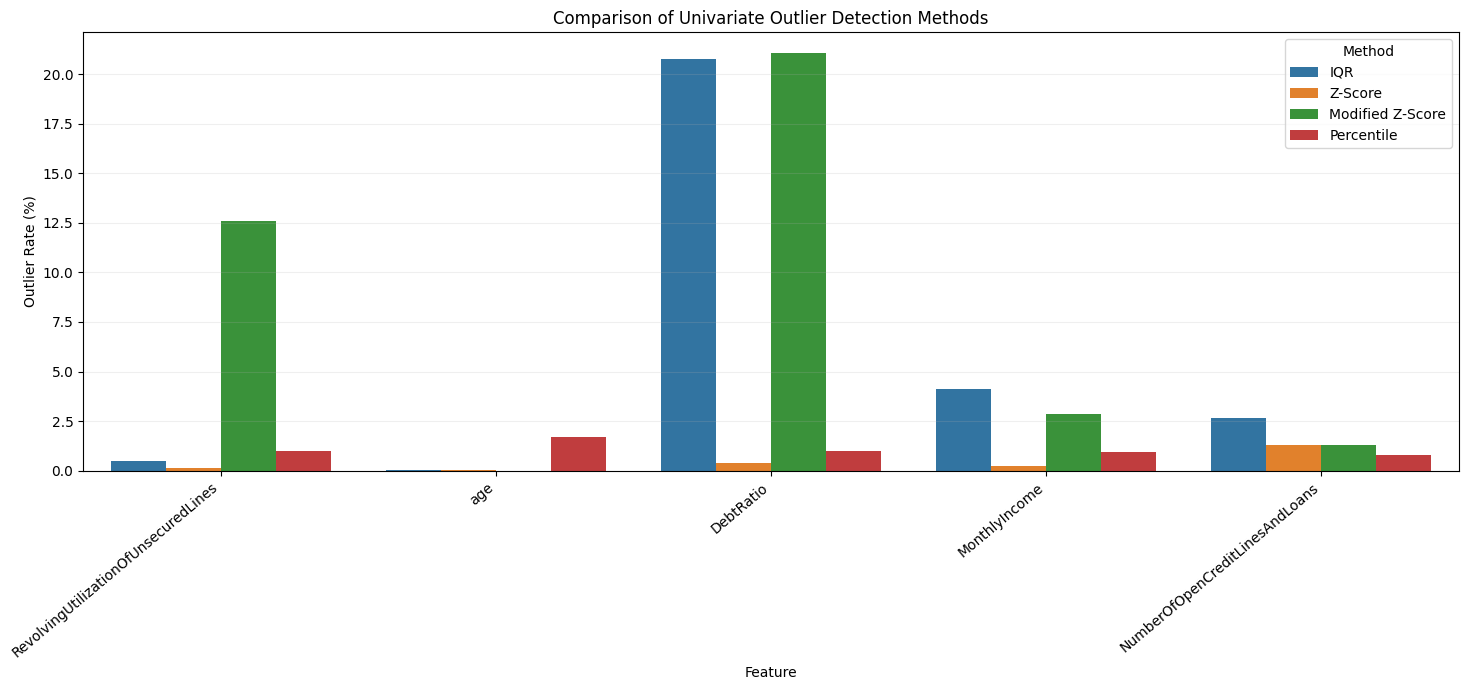

Multivariate LOF features: ['RevolvingUtilizationOfUnsecuredLines', 'age', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans']


,Feature,Method,Count,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Rate_%
0,MULTIVARIATE,LOF,120000,NaN,NaN,1200,1.0


,RevolvingUtilizationOfUnsecuredLines,age,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,LOF_Score
50198,798.0,62,1100.0,NaN,4,271.022947
127817,658.0,29,1778.0,NaN,10,248.462549
50483,1723.0,32,2253.0,NaN,2,139.301344
101972,2411.0,44,3713.0,NaN,2,103.128854
72734,312.0,83,318.0,NaN,3,100.179525
127323,825.0,72,3886.0,NaN,7,93.377605
11131,2612.0,32,4726.0,NaN,10,80.391920
29385,2128.0,49,5443.0,NaN,6,69.215049
106687,322.0,60,187.0,NaN,7,59.863679
99894,135.0,67,1761.0,NaN,8,57.120376


In [28]:
def apply_outlier_bounds(data, features, method_name, bounds_fn):

    summaries = []

    for col in features:

        s = data[col].replace([np.inf, -np.inf], np.nan).dropna()

        if s.empty:
            continue

        lower, upper = bounds_fn(s)

        if not np.isfinite(lower) or not np.isfinite(upper):
            continue

        mask = (s < lower) | (s > upper)

        summaries.append({
            "Feature": col,
            "Method": method_name,
            "Count": len(s),
            "Lower_Bound": lower,
            "Upper_Bound": upper,
            "Outlier_Count": int(mask.sum()),
            "Outlier_Rate_%": mask.mean() * 100,
        })

    return pd.DataFrame(summaries)


def detect_iqr(data, features, factor=1.5):
    def bounds(s):
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        return (np.nan, np.nan) if iqr == 0 else (q1 - factor * iqr, q3 + factor * iqr)
    return apply_outlier_bounds(data, features, "IQR", bounds)


def detect_zscore(data, features, threshold=3.0):
    def bounds(s):
        mean, std = s.mean(), s.std(ddof=0)
        return (np.nan, np.nan) if std == 0 else (mean - threshold * std, mean + threshold * std)
    return apply_outlier_bounds(data, features, "Z-Score", bounds)


def detect_modified_zscore(data, features, threshold=3.5):
    def bounds(s):
        median = s.median()
        mad = np.median(np.abs(s.to_numpy() - median))
        if mad == 0:
            return np.nan, np.nan
        distance = threshold * mad / 0.6745
        return median - distance, median + distance
    return apply_outlier_bounds(data, features, "Modified Z-Score", bounds)


def detect_percentile(data, features, lower_q=0.01, upper_q=0.99):
    def bounds(s):
        return s.quantile(lower_q), s.quantile(upper_q)
    return apply_outlier_bounds(data, features, "Percentile", bounds)


def detect_lof(data, features, n_neighbors=30, contamination=0.01):

    X = data[features].replace([np.inf, -np.inf], np.nan)
    X_scaled = RobustScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(X))

    lof = LocalOutlierFactor(
        n_neighbors=n_neighbors,
        contamination=contamination,
        algorithm="kd_tree",
        n_jobs=-1,
    )

    mask = lof.fit_predict(X_scaled) == -1

    summary = pd.DataFrame([{
        "Feature": "MULTIVARIATE",
        "Method": "LOF",
        "Count": len(X),
        "Lower_Bound": np.nan,
        "Upper_Bound": np.nan,
        "Outlier_Count": int(mask.sum()),
        "Outlier_Rate_%": mask.mean() * 100,
    }])

    lof_details = X.loc[mask].copy()
    lof_details["LOF_Score"] = -lof.negative_outlier_factor_[mask]

    return summary, lof_details


if continuous_cols:

    outlier_comparison = pd.concat([
        detect_iqr(X_eda, continuous_cols),
        detect_zscore(X_eda, continuous_cols),
        detect_modified_zscore(X_eda, continuous_cols),
        detect_percentile(X_eda, continuous_cols),
    ], ignore_index=True)

    lof_features = continuous_cols[:5]
    lof_summary, lof_details = detect_lof(X_eda, lof_features)

    comparison_matrix = outlier_comparison.pivot(
        index="Feature", columns="Method", values="Outlier_Rate_%"
    )
    display(comparison_matrix.round(3))

    plt.figure(figsize=(15, 7))
    sns.barplot(data=outlier_comparison, x="Feature", y="Outlier_Rate_%", hue="Method")
    plt.title("Comparison of Univariate Outlier Detection Methods")
    plt.ylabel("Outlier Rate (%)")
    plt.xticks(rotation=40, ha="right")
    plt.grid(axis="y", alpha=0.2)
    plt.tight_layout()
    plt.show()

    print("Multivariate LOF features:", lof_features)
    display(lof_summary.round(3))
    display(lof_details.sort_values("LOF_Score", ascending=False).head(10))

## 4.8 Pearson & Spearman Correlation

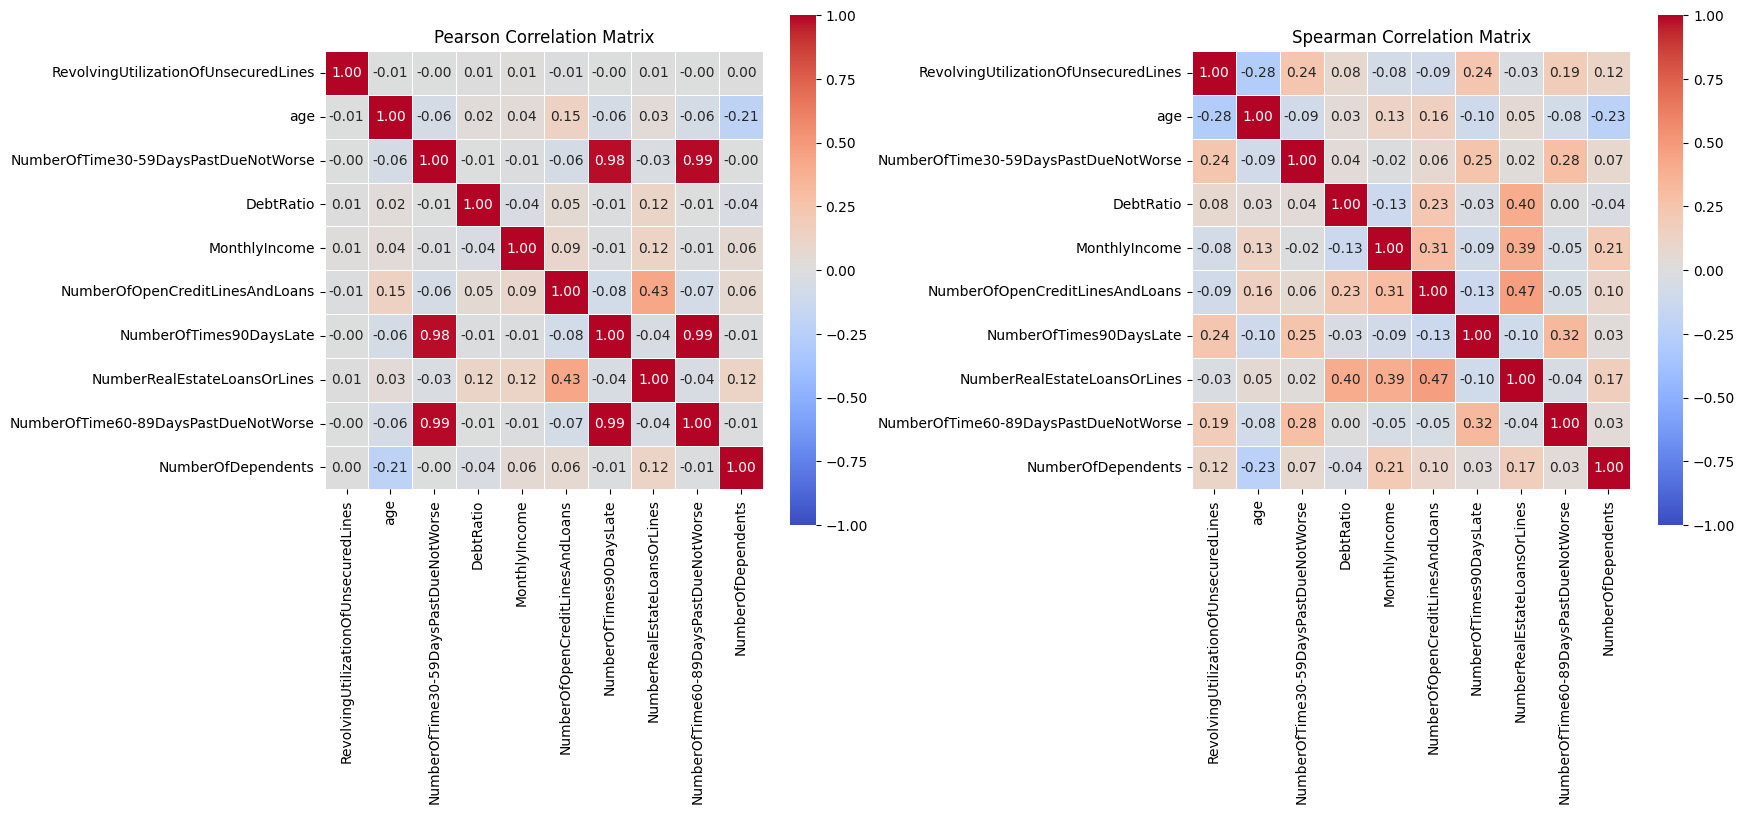

,Feature_1,Feature_2,Absolute_Difference,Pearson,Spearman
20,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTimes90DaysLate,0.7287,0.9836,0.2549
22,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,0.7050,0.9869,0.2819
40,NumberOfTimes90DaysLate,NumberOfTime60-89DaysPastDueNotWorse,0.6703,0.9928,0.3226
27,DebtRatio,NumberRealEstateLoansOrLines,0.2841,0.1171,0.4011
0,RevolvingUtilizationOfUnsecuredLines,age,0.2700,-0.0073,-0.2773
32,MonthlyIncome,NumberRealEstateLoansOrLines,0.2690,0.1230,0.3920
5,RevolvingUtilizationOfUnsecuredLines,NumberOfTimes90DaysLate,0.2404,-0.0010,0.2394
1,RevolvingUtilizationOfUnsecuredLines,NumberOfTime30-59DaysPastDueNotWorse,0.2387,-0.0013,0.2374
30,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,0.2218,0.0890,0.3108
7,RevolvingUtilizationOfUnsecuredLines,NumberOfTime60-89DaysPastDueNotWorse,0.1901,-0.0010,0.1891


In [29]:
if len(numeric_cols) > 1:

    numeric_data = X_eda[numeric_cols]
    pearson_corr = numeric_data.corr(method="pearson")
    spearman_corr = numeric_data.corr(method="spearman")

    size = max(8, 0.6 * len(numeric_cols))
    fig, axes = plt.subplots(1, 2, figsize=(2.2 * size, size))

    for ax, corr, method in zip(axes, [pearson_corr, spearman_corr], ["Pearson", "Spearman"]):
        sns.heatmap(corr, annot=len(numeric_cols) <= 20, fmt=".2f", cmap="coolwarm",
                    center=0, vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax)
        ax.set_title(f"{method} Correlation Matrix")

    plt.tight_layout()
    plt.show()

    # Largest Pearson - Spearman differences
    upper_mask = np.triu(np.ones(pearson_corr.shape, dtype=bool), k=1)

    corr_pairs = (
        (pearson_corr - spearman_corr).abs()
        .where(upper_mask)
        .stack()
        .reset_index()
    )
    corr_pairs.columns = ["Feature_1", "Feature_2", "Absolute_Difference"]
    corr_pairs["Pearson"] = [pearson_corr.loc[a, b] for a, b in zip(corr_pairs["Feature_1"], corr_pairs["Feature_2"])]
    corr_pairs["Spearman"] = [spearman_corr.loc[a, b] for a, b in zip(corr_pairs["Feature_1"], corr_pairs["Feature_2"])]

    display(corr_pairs.sort_values("Absolute_Difference", ascending=False).head(15).round(4))

In [30]:
# Diagnostic: Investigate suspicious delinquency values
delay_cols = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate"
]

# Frequency of suspicious values
for col in delay_cols:
    print(f"\n{col}")
    print(X_train[col].value_counts().loc[
        lambda s: s.index.isin([96, 98])
    ])

# Rows containing at least one suspicious value
special_mask = X_train[delay_cols].isin([96, 98]).any(axis=1)

print("\nRows containing 96 or 98:", special_mask.sum())

# Correlation comparison
print("\nOriginal Pearson Correlation:")
display(X_train[delay_cols].corr().round(4))

print("\nPearson Correlation excluding 96/98 rows:")
display(
    X_train.loc[~special_mask, delay_cols]
    .corr()
    .round(4)
)

# Target distribution for suspicious rows
print("\nTarget distribution by suspicious-value status:")
display(
    pd.crosstab(
        special_mask,
        y_train,
        normalize="index"
    ).round(4)
)


NumberOfTime30-59DaysPastDueNotWorse
NumberOfTime30-59DaysPastDueNotWorse
98    212
96      2
Name: count, dtype: int64

NumberOfTime60-89DaysPastDueNotWorse
NumberOfTime60-89DaysPastDueNotWorse
98    212
96      2
Name: count, dtype: int64

NumberOfTimes90DaysLate
NumberOfTimes90DaysLate
98    212
96      2
Name: count, dtype: int64

Rows containing 96 or 98: 214

Original Pearson Correlation:


,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate
NumberOfTime30-59DaysPastDueNotWorse,1.0000,0.9869,0.9836
NumberOfTime60-89DaysPastDueNotWorse,0.9869,1.0000,0.9928
NumberOfTimes90DaysLate,0.9836,0.9928,1.0000



Pearson Correlation excluding 96/98 rows:


,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate
NumberOfTime30-59DaysPastDueNotWorse,1.0000,0.3062,0.2209
NumberOfTime60-89DaysPastDueNotWorse,0.3062,1.0000,0.2959
NumberOfTimes90DaysLate,0.2209,0.2959,1.0000



Target distribution by suspicious-value status:


SeriousDlqin2yrs,0,1
row_0,,
False,0.9340,0.0660
True,0.4533,0.5467


# 5. Numerical Features vs Target

## 5.1 Class-Wise Summary

In [31]:
def classwise_numeric_summary(X, y, cols):

    results = []

    for feature in cols:
        for code, group in X[cols].groupby(y):

            s = group[feature].dropna()

            results.append({
                "Feature": feature,
                "Class": CLASS_LABELS[code],
                "Count": len(s),
                "Missing_%": group[feature].isna().mean() * 100,
                "Mean": s.mean(),
                "Median": s.median(),
                "Std": s.std(),
                "Q1": s.quantile(0.25),
                "Q3": s.quantile(0.75),
                "IQR": s.quantile(0.75) - s.quantile(0.25),
            })

    return pd.DataFrame(results)


if numeric_cols:
    display(classwise_numeric_summary(X_eda, y_train, numeric_cols).round(3))

,Feature,Class,Count,Missing_%,Mean,Median,Std,Q1,Q3,IQR
0,RevolvingUtilizationOfUnsecuredLines,0,111979,0.000,6.190,0.132,259.296,0.027,0.486,0.459
1,RevolvingUtilizationOfUnsecuredLines,1,8021,0.000,5.281,0.833,147.383,0.399,1.000,0.601
2,age,0,111979,0.000,52.732,52.000,14.796,42.000,63.000,21.000
3,age,1,8021,0.000,46.089,46.000,12.919,36.000,54.000,18.000
4,NumberOfTime30-59DaysPastDueNotWorse,0,111979,0.000,0.280,0.000,2.938,0.000,0.000,0.000
5,NumberOfTime30-59DaysPastDueNotWorse,1,8021,0.000,2.374,0.000,11.708,0.000,2.000,2.000
6,DebtRatio,0,111979,0.000,357.125,0.363,2145.412,0.174,0.859,0.685
7,DebtRatio,1,8021,0.000,284.512,0.426,1148.501,0.193,0.875,0.682
8,MonthlyIncome,0,89623,19.964,6725.603,5434.000,14967.734,3450.000,8333.000,4883.000
9,MonthlyIncome,1,6702,16.444,5660.660,4500.000,6486.680,2986.500,6808.750,3822.250


## 5.2 Boxplots by Class

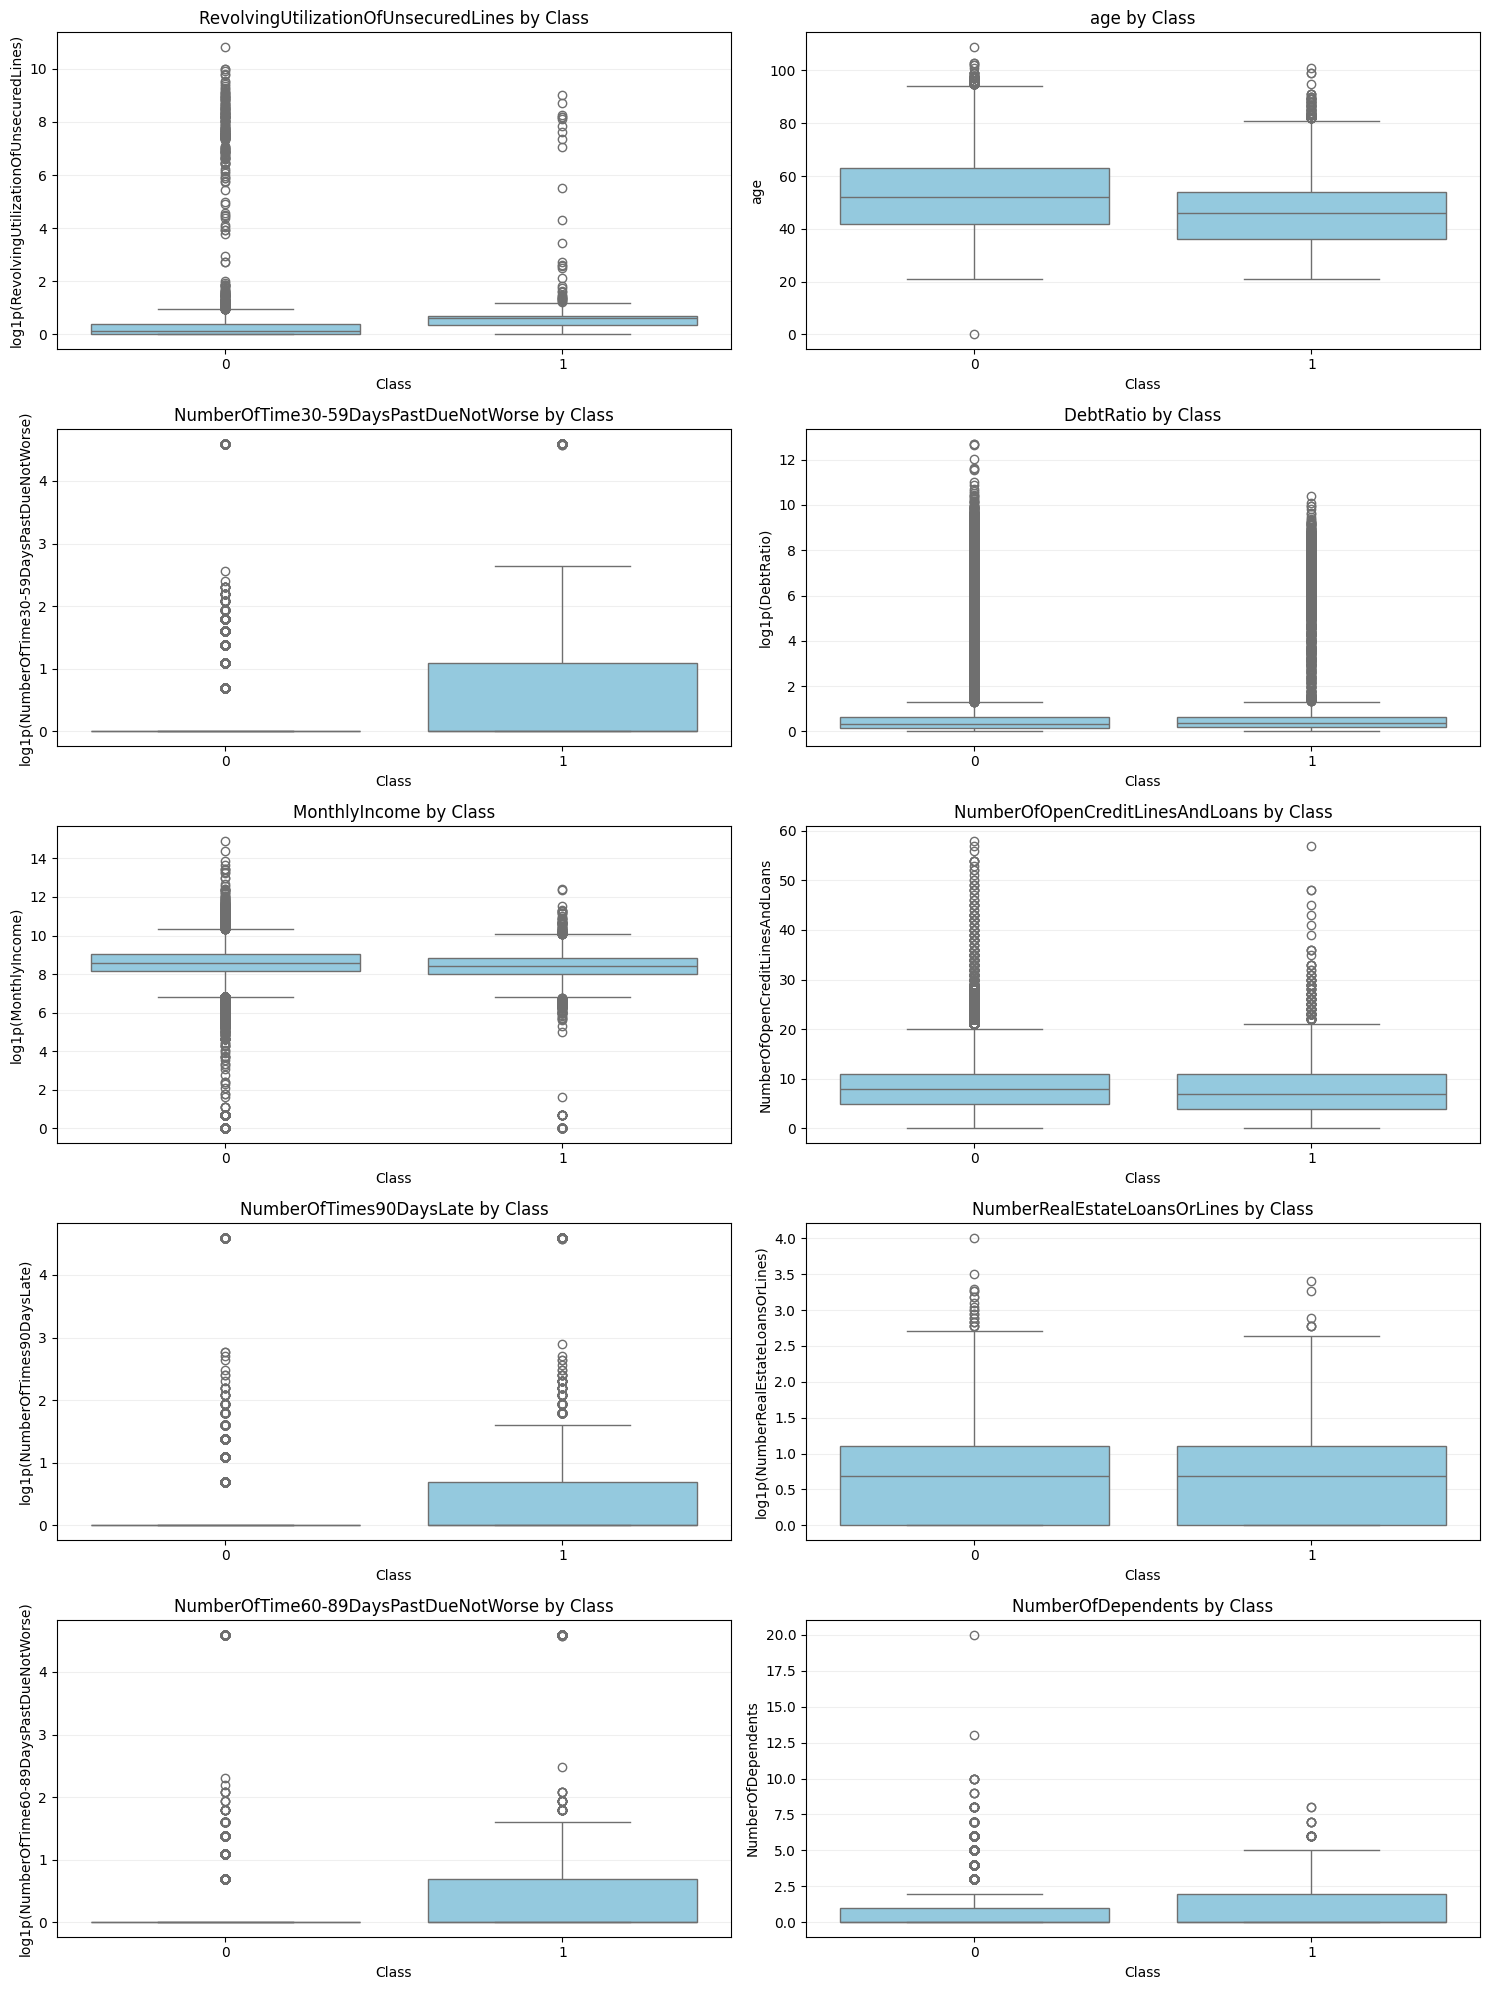

In [32]:
def plot_numeric_features_by_target(X, y, cols, ncols=2):

    plot_df = X[cols].copy()
    plot_df["Class"] = y.map(dict(enumerate(CLASS_LABELS)))

    # Log scale for visualization only
    log_features = {c for c in cols if X[c].min() >= 0 and X[c].skew() > 2}

    nrows = math.ceil(len(cols) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
    axes = np.asarray(axes).ravel()

    for ax, feature in zip(axes, cols):

        data = plot_df[["Class", feature]].dropna().copy()

        if feature in log_features:
            data[feature] = np.log1p(data[feature])

        sns.boxplot(data=data, x="Class", y=feature, order=CLASS_LABELS,
                    color="skyblue", showfliers=True, ax=ax)

        ax.set_title(f"{feature} by Class")
        ax.set_ylabel(f"log1p({feature})" if feature in log_features else feature)
        ax.grid(axis="y", alpha=0.2)

    for ax in axes[len(cols):]:
        ax.remove()

    plt.tight_layout()
    plt.show()


if numeric_cols:
    plot_numeric_features_by_target(X_eda, y_train, numeric_cols)

## 5.3 Class-Wise Empirical CDF

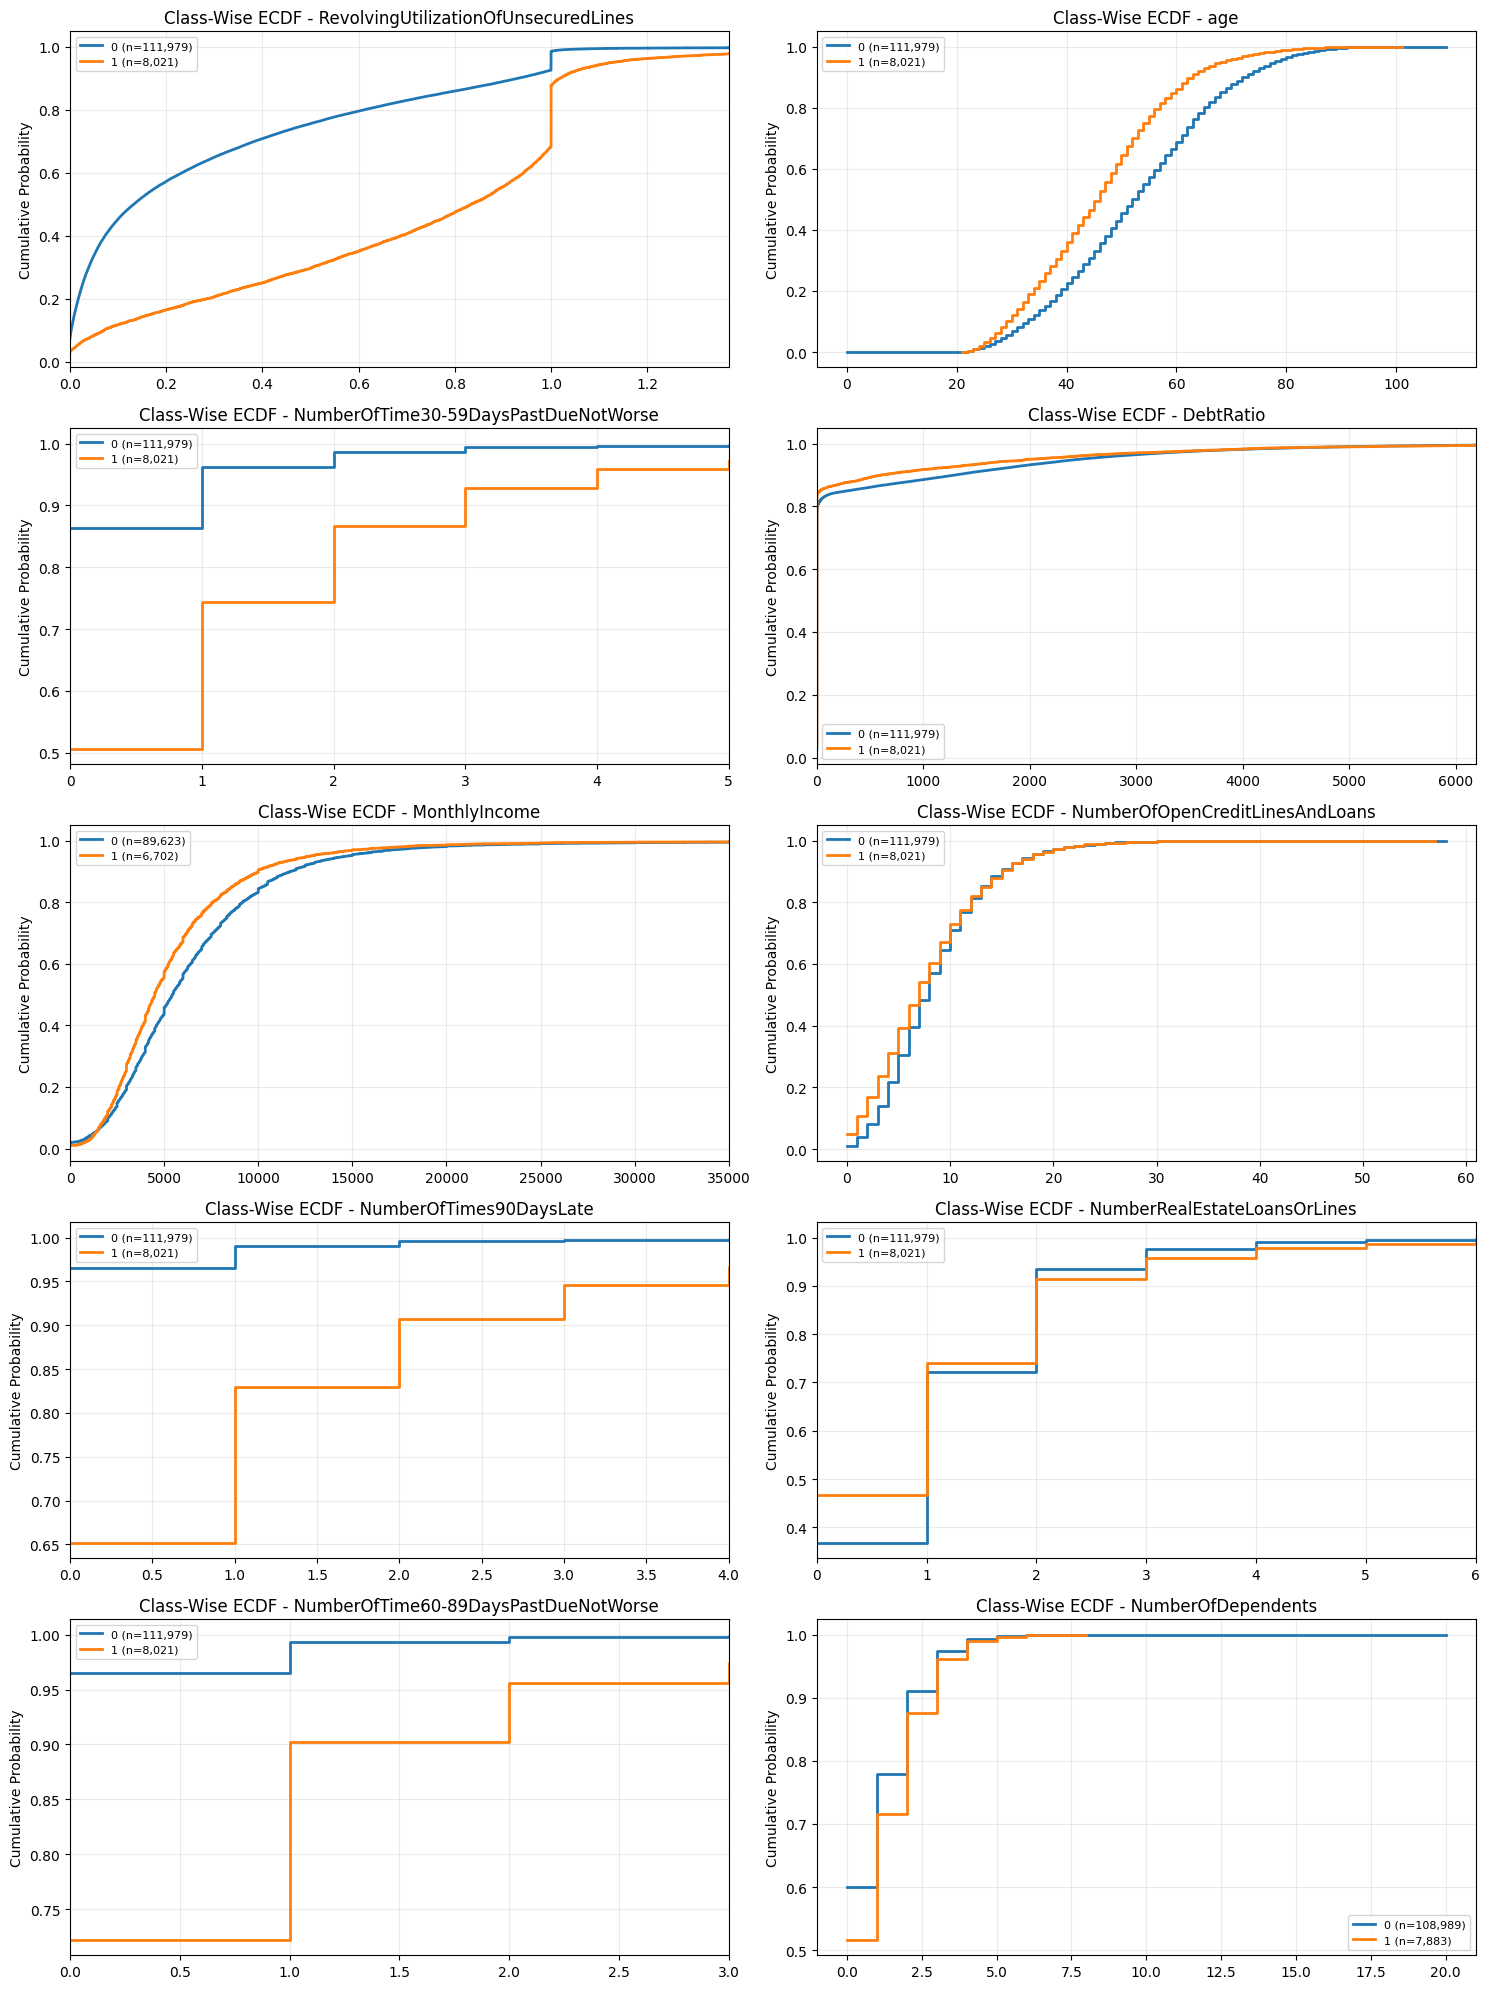

In [34]:
def plot_classwise_ecdf(X, y, cols, ncols=2):

    nrows = math.ceil(len(cols) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
    axes = np.asarray(axes).ravel()

    for ax, feature in zip(axes, cols):

        all_values = X[feature].dropna()

        for code in range(N_CLASSES):

            s = X.loc[y == code, feature].dropna().to_numpy()

            if len(s) == 0:
                continue

            values, counts = np.unique(s, return_counts=True)
            ax.step(values, np.cumsum(counts) / len(s), where="post", linewidth=2,
                    label=f"{CLASS_LABELS[code]} (n={len(s):,})")

        # Zoom for highly skewed features (visual only)
        if abs(all_values.skew()) > 2:
            ax.set_xlim(all_values.quantile(0.005), all_values.quantile(0.995))

        ax.set_title(f"Class-Wise ECDF - {feature}")
        ax.set_ylabel("Cumulative Probability")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.25)

    for ax in axes[len(cols):]:
        ax.remove()

    plt.tight_layout()
    plt.show()


if numeric_cols:
    plot_classwise_ecdf(X_eda, y_train, numeric_cols)

## 5.4 Class Rate by Quantile with 95% Wilson CI

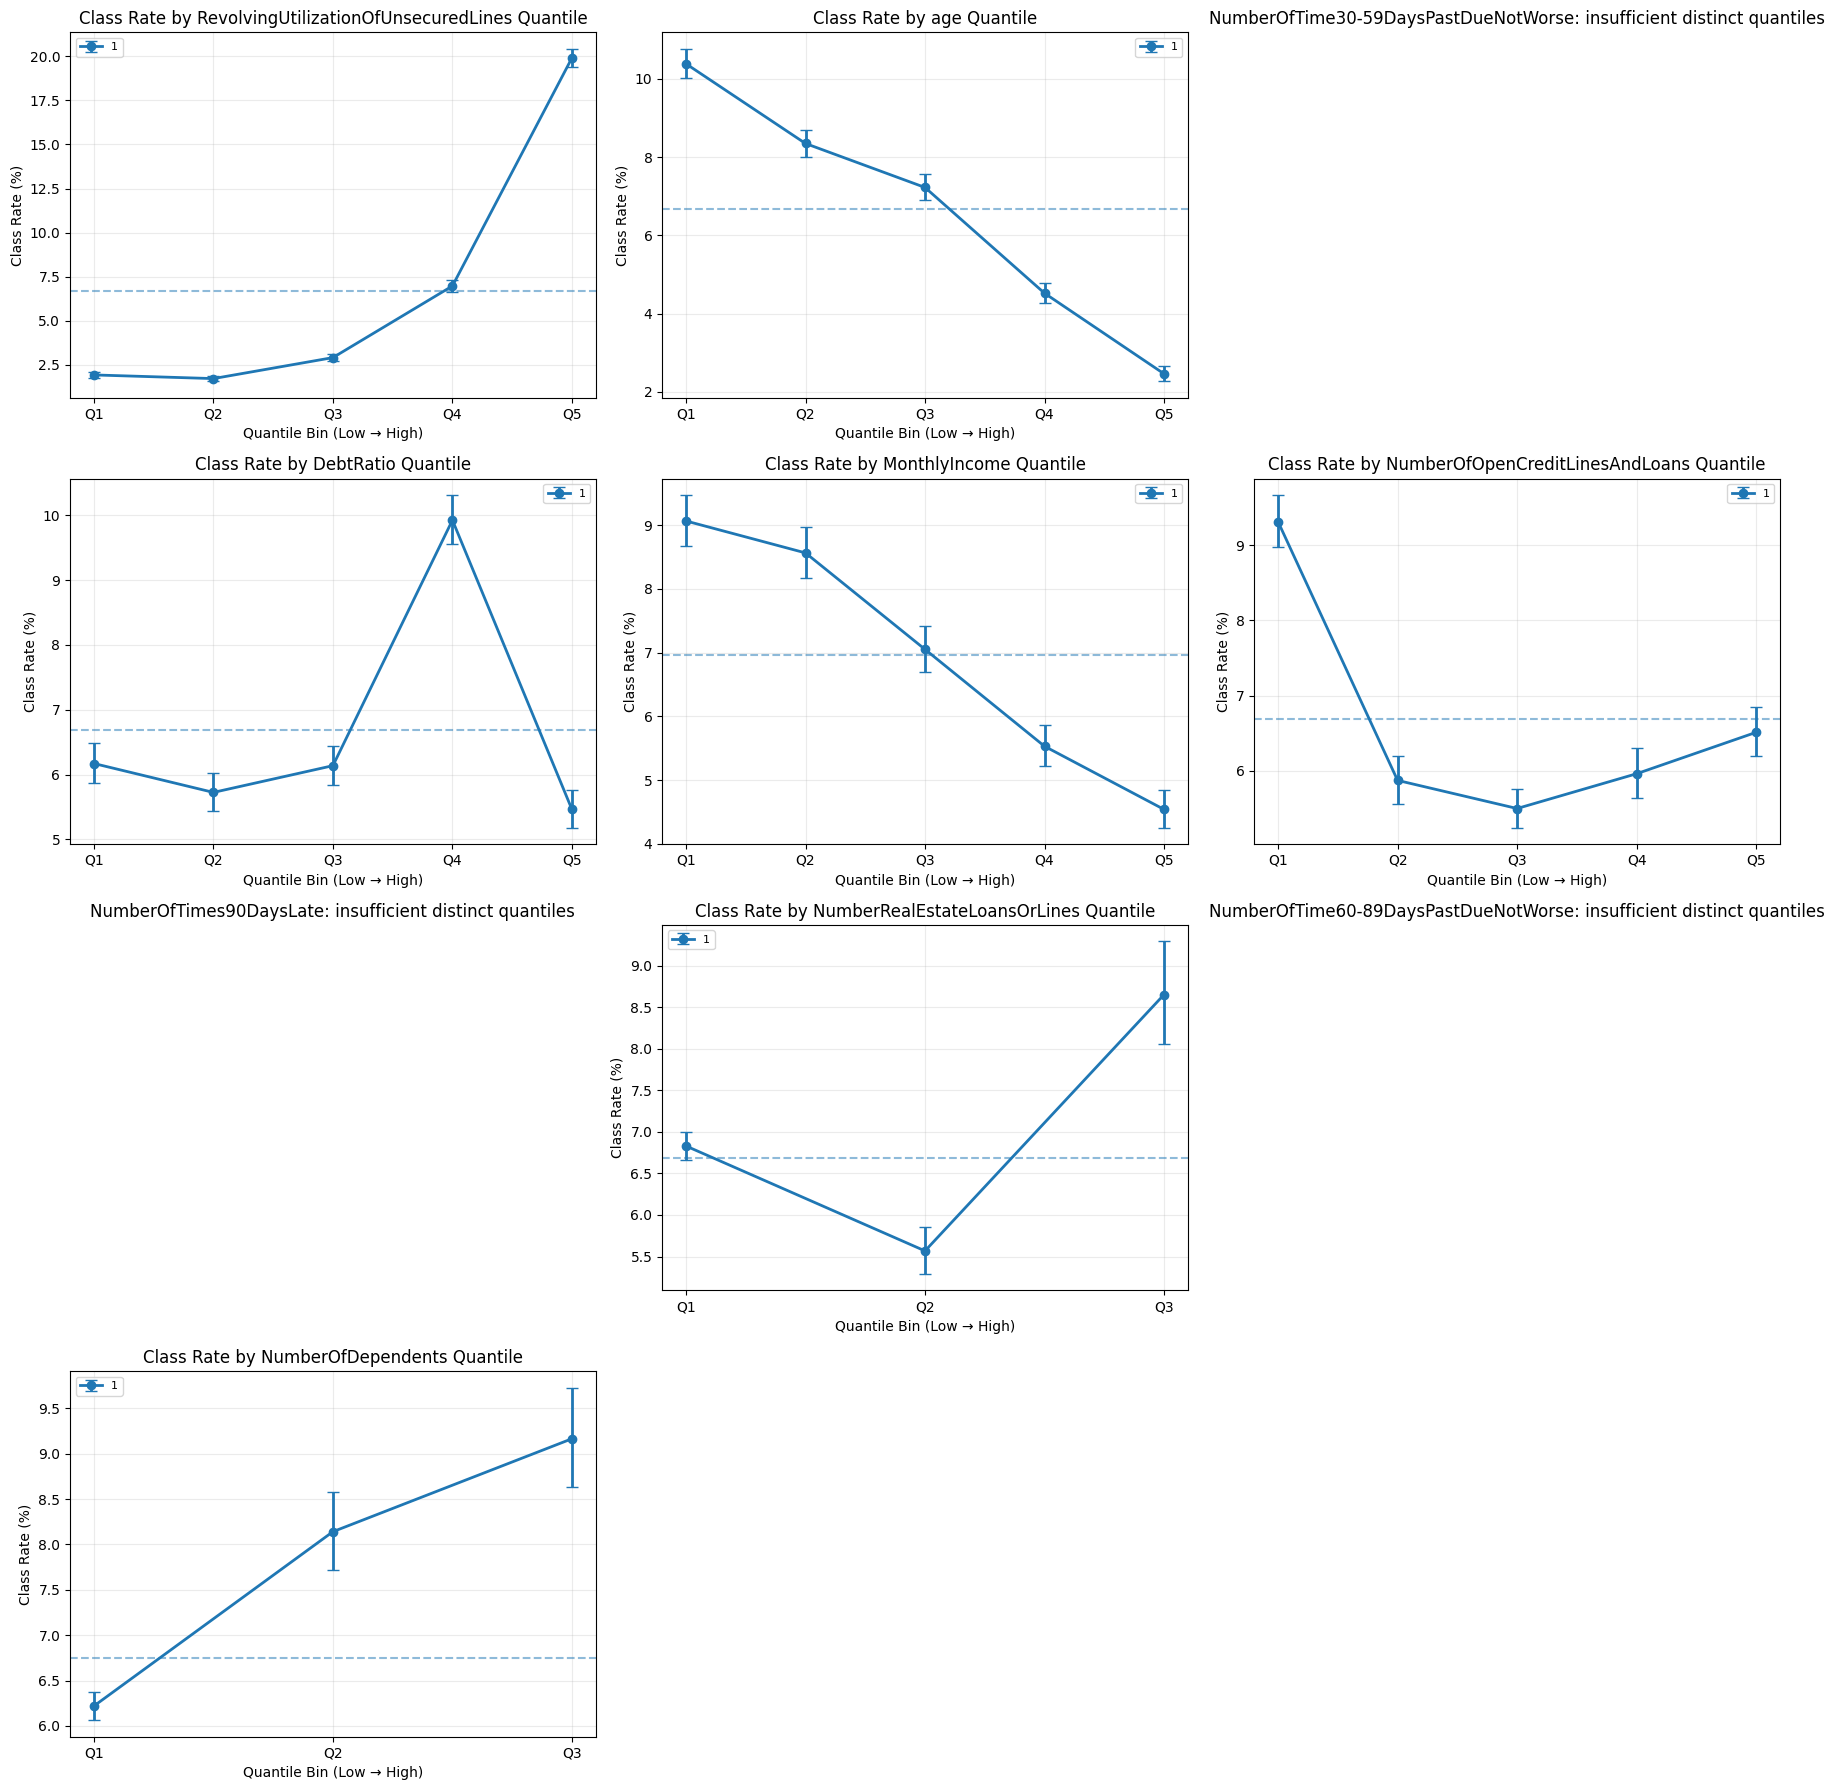

,Feature,Quantile,Bin,Class,Count,Class_Count,Rate_%,CI_Lower_%,CI_Upper_%
0,RevolvingUtilizationOfUnsecuredLines,Q1,"(-0.001, 0.0191]",1,24000,461,1.921,1.755,2.102
1,RevolvingUtilizationOfUnsecuredLines,Q2,"(0.0191, 0.0826]",1,24000,411,1.713,1.556,1.885
2,RevolvingUtilizationOfUnsecuredLines,Q3,"(0.0826, 0.271]",1,24000,697,2.904,2.699,3.124
3,RevolvingUtilizationOfUnsecuredLines,Q4,"(0.271, 0.696]",1,24000,1673,6.971,6.655,7.300
4,RevolvingUtilizationOfUnsecuredLines,Q5,"(0.696, 50708.0]",1,24000,4779,19.912,19.412,20.423
5,age,Q1,"(-0.001, 39.0]",1,25636,2662,10.384,10.016,10.763
6,age,Q2,"(39.0, 48.0]",1,24390,2036,8.348,8.007,8.701
7,age,Q3,"(48.0, 56.0]",1,23268,1681,7.225,6.899,7.564
8,age,Q4,"(56.0, 65.0]",1,23856,1079,4.523,4.267,4.794
9,age,Q5,"(65.0, 109.0]",1,22850,563,2.464,2.271,2.673


In [35]:
def target_rate_by_quantile(X, y, cols, q=5, ncols=3):

    classes_to_plot = [1] if IS_BINARY else list(range(N_CLASSES))
    nrows = math.ceil(len(cols) / ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4.5 * nrows))
    axes = np.asarray(axes).ravel()

    results = []

    for ax, feature in zip(axes, cols):

        temp = pd.DataFrame({"value": X[feature], "target": y}).dropna(subset=["value"])
        temp["bin"] = pd.qcut(temp["value"], q=q, duplicates="drop")

        if temp["bin"].nunique() < 2:
            ax.set_title(f"{feature}: insufficient distinct quantiles")
            ax.axis("off")
            continue

        grouped = temp.groupby("bin", observed=True)["target"]
        counts = grouped.size()
        labels = [f"Q{i + 1}" for i in range(len(counts))]

        for code in classes_to_plot:

            hits = grouped.apply(lambda s: (s == code).sum())
            rate = hits / counts
            lower, upper = proportion_confint(hits, counts, alpha=0.05, method="wilson")

            container = ax.errorbar(
                labels, rate * 100,
                yerr=[np.clip(rate - lower, 0, None) * 100, np.clip(upper - rate, 0, None) * 100],
                fmt="o-", capsize=4, linewidth=2, label=CLASS_LABELS[code],
            )

            ax.axhline((temp["target"] == code).mean() * 100,
                       color=container[0].get_color(), linestyle="--", alpha=0.5)

            for label, interval, n, h, r, lo, hi in zip(
                labels, counts.index, counts, hits, rate, lower, upper
            ):
                results.append({
                    "Feature": feature, "Quantile": label, "Bin": interval,
                    "Class": CLASS_LABELS[code], "Count": n, "Class_Count": h,
                    "Rate_%": r * 100, "CI_Lower_%": lo * 100, "CI_Upper_%": hi * 100,
                })

        ax.set_title(f"Class Rate by {feature} Quantile")
        ax.set_xlabel("Quantile Bin (Low → High)")
        ax.set_ylabel("Class Rate (%)")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.25)

    for ax in axes[len(cols):]:
        ax.remove()

    plt.tight_layout()
    plt.show()

    return pd.DataFrame(results)


if numeric_cols:
    quantile_rate_summary = target_rate_by_quantile(X_eda, y_train, numeric_cols)
    display(quantile_rate_summary.round(3))

In [39]:
# 5.4 — Additional Risk Analysis for Delinquency Features

from statsmodels.stats.proportion import proportion_confint

delay_cols = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate"
]

def delinquency_risk_analysis(X, y, columns):

    results = []

    for col in columns:

        s = X[col]

        groups = np.select(
            [
                s.eq(0),
                s.eq(1),
                s.eq(2),
                s.between(3, 95),
                s.isin([96, 98])
            ],
            ["0", "1", "2", "3-95", "96/98"],
            default="Other"
        )

        temp = pd.DataFrame({
            "Group": groups,
            "Target": y.to_numpy()
        })

        summary = (
            temp.groupby("Group")["Target"]
            .agg(Count="size", Class_1_Count="sum")
        )

        lower, upper = proportion_confint(
            summary["Class_1_Count"],
            summary["Count"],
            alpha=0.05,
            method="wilson"
        )

        summary["Risk_Rate_%"] = (
            summary["Class_1_Count"] / summary["Count"] * 100
        )

        summary["CI_Lower_%"] = lower * 100
        summary["CI_Upper_%"] = upper * 100
        summary["Feature"] = col

        results.append(summary.reset_index())

    return pd.concat(results, ignore_index=True)


delinquency_risk_summary = delinquency_risk_analysis(
    X_train,
    y_train,
    delay_cols
)

display(
    delinquency_risk_summary[
        [
            "Feature", "Group", "Count",
            "Class_1_Count", "Risk_Rate_%",
            "CI_Lower_%", "CI_Upper_%"
        ]
    ].round(3)
)

,Feature,Group,Count,Class_1_Count,Risk_Rate_%,CI_Lower_%,CI_Upper_%
0,NumberOfTime30-59DaysPastDueNotWorse,0,100794,4059,4.027,3.907,4.150
1,NumberOfTime30-59DaysPastDueNotWorse,1,12844,1908,14.855,14.251,15.481
2,NumberOfTime30-59DaysPastDueNotWorse,2,3689,979,26.538,25.138,27.987
3,NumberOfTime30-59DaysPastDueNotWorse,3-95,2459,958,38.959,37.050,40.902
4,NumberOfTime30-59DaysPastDueNotWorse,96/98,214,117,54.673,47.979,61.202
5,NumberOfTime60-89DaysPastDueNotWorse,0,113881,5791,5.085,4.959,5.214
6,NumberOfTime60-89DaysPastDueNotWorse,1,4626,1443,31.193,29.874,32.543
7,NumberOfTime60-89DaysPastDueNotWorse,2,883,432,48.924,45.639,52.219
8,NumberOfTime60-89DaysPastDueNotWorse,3-95,396,238,60.101,55.203,64.805
9,NumberOfTime60-89DaysPastDueNotWorse,96/98,214,117,54.673,47.979,61.202


# 6. Modeling Setup

## 6.0 Domain Features (Optional)

In [42]:
# Row-wise domain features, applied inside the pipeline (saved with the model).
# Use only the row's own values and fixed constants — no statistics computed from the data,
# no target, no information recorded after the prediction moment.
DOMAIN_FEATURES = None
# Example (UCI credit card clients):
# def add_domain_features(df):
#     for k in range(1, 7):
#         df[f"utilization_{k}"] = df[f"BILL_AMT{k}"] / df["LIMIT_BAL"]
#     return df
# DOMAIN_FEATURES = add_domain_features

## 6.1 Custom Transformers

In [44]:
class DropColumns(BaseEstimator, TransformerMixin):
    """ Removes unwanted columns """
    def __init__(self, columns=None):
        self.columns = columns

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return X.drop(columns=self.columns or [], errors="ignore").copy()


class UpperQuantileClipper(BaseEstimator, TransformerMixin):
    """ Limits excessively large values """
    def __init__(self, quantiles=None):
        self.quantiles = quantiles

    def fit(self, X, y=None):
        self.bounds_ = {}
        for col, q in (self.quantiles or {}).items():
            if col in X.columns:
                values = pd.to_numeric(X[col], errors="coerce").replace([np.inf, -np.inf], np.nan)
                self.bounds_[col] = values.quantile(q)
        return self

    def transform(self, X):
        X = X.copy()
        for col, upper in self.bounds_.items():
            X[col] = X[col].clip(upper=upper)
        return X


class FeatureEngineer(BaseEstimator, TransformerMixin):
    """Generic manual features; entries referring to absent columns are skipped.

    Engineered names usable in `cat_interactions`:
    '<col>_is_missing', '<col>_is_zero', '<col>_cat'.
    """

    def __init__(self, ratio_pairs=None, cat_interactions=None, log_features="auto",
                 missing_indicators=True, zero_indicators=True,
                 discrete_as_category=True, discrete_max_unique=10, skew_threshold=1.0):
        self.ratio_pairs = ratio_pairs
        self.cat_interactions = cat_interactions
        self.log_features = log_features
        self.missing_indicators = missing_indicators
        self.zero_indicators = zero_indicators
        self.discrete_as_category = discrete_as_category
        self.discrete_max_unique = discrete_max_unique
        self.skew_threshold = skew_threshold

    @staticmethod
    def _as_label(s):
        if pd.api.types.is_numeric_dtype(s):
            return s.map(lambda v: "MISSING" if pd.isna(v)
                         else (str(int(v)) if float(v).is_integer() else str(v)))
        return s.astype(object).fillna("MISSING").astype(str)

    def fit(self, X, y=None):
        num = X.select_dtypes(include=np.number)
        n_unique = num.nunique(dropna=True)

        if self.log_features == "auto":
            self.log_features_ = [
                c for c in num.columns
                if n_unique[c] > 10 and num[c].min() >= 0 and num[c].skew() > self.skew_threshold
            ]
        else:
            self.log_features_ = [c for c in (self.log_features or []) if c in num.columns]

        self.missing_cols_ = (
            [c for c in num.columns if num[c].isna().any()] if self.missing_indicators else []
        )

        # Zero indicators only for non-binary features (for 0/1 columns they duplicate the feature)
        self.zero_cols_ = (
            [c for c in num.columns
             if n_unique[c] > 2 and 0.001 <= num[c].eq(0).mean() <= 0.5]
            if self.zero_indicators else []
        )

        # Low-cardinality integer features as categories (non-monotone effects for linear models)
        self.discrete_cols_ = (
            [c for c in num.columns
             if 3 <= n_unique[c] <= self.discrete_max_unique
             and np.allclose(num[c].dropna(), np.round(num[c].dropna()))]
            if self.discrete_as_category else []
        )

        self.ratio_pairs_ = [
            (a, b) for a, b in (self.ratio_pairs or [])
            if a in num.columns and b in num.columns
        ]

        available = (
            set(X.columns)
            | {f"{c}_is_missing" for c in self.missing_cols_}
            | {f"{c}_is_zero" for c in self.zero_cols_}
            | {f"{c}_cat" for c in self.discrete_cols_}
        )
        self.cat_interactions_ = [
            (a, b) for a, b in (self.cat_interactions or [])
            if a in available and b in available
        ]

        return self

    def transform(self, X):

        check_is_fitted(self, "log_features_")
        X = X.copy()

        for col in self.missing_cols_:
            X[f"{col}_is_missing"] = X[col].isna().astype("int8")

        for col in self.zero_cols_:
            X[f"{col}_is_zero"] = X[col].eq(0).astype("int8")

        for col in self.discrete_cols_:
            X[f"{col}_cat"] = self._as_label(X[col]).astype(object)

        for col in self.log_features_:
            X[f"log_{col}"] = np.log1p(X[col].clip(lower=0))

        for a, b in self.ratio_pairs_:
            ratio = X[a] / X[b].where(X[b] != 0)
            X[f"ratio_{a}_to_{b}"] = ratio
            X[f"log_ratio_{a}_to_{b}"] = np.sign(ratio) * np.log1p(ratio.abs())

        for a, b in self.cat_interactions_:
            X[f"{a}_x_{b}"] = (self._as_label(X[a]) + "__" + self._as_label(X[b])).astype(object)

        return X.replace([np.inf, -np.inf], np.nan)


class QuantileBinner(BaseEstimator, TransformerMixin):
    """Quantile bins for ratio features (default: columns starting with 'ratio_')."""

    def __init__(self, features=None, n_bins=5):
        self.features = features
        self.n_bins = n_bins

    def fit(self, X, y=None):

        features = self.features or [c for c in X.columns if str(c).startswith("ratio_")]
        self.edges_ = {}

        for feature in features:

            if feature not in X.columns:
                continue

            values = pd.to_numeric(X[feature], errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()

            if values.nunique() < 2:
                continue

            _, edges = pd.qcut(values, q=self.n_bins, retbins=True, duplicates="drop")

            if len(edges) >= 3:
                self.edges_[feature] = edges[1:-1]

        return self

    def transform(self, X):

        check_is_fitted(self, "edges_")
        X = X.copy()

        for feature, internal_edges in self.edges_.items():

            values = pd.to_numeric(X[feature], errors="coerce").replace([np.inf, -np.inf], np.nan)
            boundaries = np.r_[-np.inf, internal_edges, np.inf]
            labels = [f"Q{i + 1}" for i in range(len(boundaries) - 1)]

            X[f"{feature}_qbin"] = (
                pd.cut(values, bins=boundaries, labels=labels, include_lowest=True)
                .astype(object)
                .fillna("MISSING")
            )

        return X


class AutoNumericFeatureGenerator(BaseEstimator, TransformerMixin):
    """ Generates automatic interaction and ratio features """
    def __init__(self, base_features=None):
        self.base_features = base_features

    def fit(self, X, y=None):

        if self.base_features is None:
            self.features_ = [
                c for c in X.select_dtypes(include=np.number).columns
                if X[c].nunique(dropna=True) > 10
            ][:6]
        else:
            self.features_ = [c for c in self.base_features if c in X.columns]

        return self

    def transform(self, X):

        X = X.copy()
        logs = {}

        # Signed log transformations
        for col in self.features_:
            s = pd.to_numeric(X[col], errors="coerce").replace([np.inf, -np.inf], np.nan)
            logs[col] = np.sign(s) * np.log1p(np.abs(s))
            X[f"auto_log_{col}"] = logs[col]
            X[f"auto_log_sq_{col}"] = logs[col] ** 2

        # Pairwise interactions and safe ratios
        for i, a in enumerate(self.features_):
            for b in self.features_[i + 1:]:
                X[f"auto_inter_{a}_{b}"] = logs[a] * logs[b]
                denominator = X[b].where(X[b].abs() > 1e-8)
                ratio = X[a] / denominator
                X[f"auto_ratio_{a}_{b}"] = np.sign(ratio) * np.log1p(np.abs(ratio))

        return X.replace([np.inf, -np.inf], np.nan)


class SplineFeatures(BaseEstimator, TransformerMixin):
    """Cubic B-spline basis expansion of continuous features (penalized regression spline / GAM style).

    Knots at training quantiles (duplicates removed), linear extrapolation outside the
    boundary knots. Combined with an L2-penalized linear model this is a penalized
    regression spline: logit(p) = b0 + sum_j f_j(x_j).
    """

    def __init__(self, features=None, n_knots=5, degree=3, keep_original=True):
        self.features = features
        self.n_knots = n_knots
        self.degree = degree
        self.keep_original = keep_original

    def fit(self, X, y=None):

        if self.features is None:
            num = X.select_dtypes(include=np.number)
            candidates = [c for c in num.columns if num[c].nunique(dropna=True) > 10]
        else:
            candidates = [c for c in self.features if c in X.columns]

        self.splines_, self.medians_ = {}, {}

        for col in candidates:
            values = pd.to_numeric(X[col], errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
            if values.nunique() < 4:
                continue

            knots = np.unique(np.quantile(values, np.linspace(0, 1, self.n_knots)))
            if len(knots) < 3:
                knots = np.linspace(values.min(), values.max(), self.n_knots)

            spline = SplineTransformer(
                knots=knots.reshape(-1, 1),
                degree=self.degree,
                include_bias=False,
                extrapolation="linear",
            ).set_output(transform="default")

            self.splines_[col] = spline.fit(values.to_numpy().reshape(-1, 1))
            self.medians_[col] = float(values.median())

        return self

    def transform(self, X):

        check_is_fitted(self, "splines_")
        X = X.copy()
        blocks = []

        for col, spline in self.splines_.items():
            values = (
                pd.to_numeric(X[col], errors="coerce")
                .replace([np.inf, -np.inf], np.nan)
                .fillna(self.medians_[col])
            )
            basis = np.asarray(spline.transform(values.to_numpy().reshape(-1, 1)))
            blocks.append(pd.DataFrame(
                basis, index=X.index,
                columns=[f"{col}_spline_{i}" for i in range(basis.shape[1])],
            ))

        if not self.keep_original:
            X = X.drop(columns=list(self.splines_))

        return pd.concat([X] + blocks, axis=1) if blocks else X


class TransformerChain(BaseEstimator, TransformerMixin):
    """Sequential transformers in one step (imblearn pipelines cannot nest Pipelines)."""

    def __init__(self, steps=None):
        self.steps = steps

    def fit(self, X, y=None):
        self.steps_ = []
        for step in self.steps or []:
            fitted = clone(step).fit(X, y)
            X = fitted.transform(X)
            self.steps_.append(fitted)
        return self

    def transform(self, X):
        check_is_fitted(self, "steps_")
        for step in self.steps_:
            X = step.transform(X)
        return X


class FeatureNameCleaner(BaseEstimator, TransformerMixin):
    """Model-safe column names (LightGBM/XGBoost reject some characters)."""

    def fit(self, X, y=None):
        self.columns_, used = [], set()
        for col in map(str, X.columns):
            base = re.sub(r"[^0-9a-zA-Z_]+", "_", col).strip("_") or "feature"
            name, suffix = base, 1
            while name in used:
                name = f"{base}_{suffix}"
                suffix += 1
            self.columns_.append(name)
            used.add(name)
        return self

    def transform(self, X):
        check_is_fitted(self, "columns_")
        X = pd.DataFrame(X).copy()
        X.columns = self.columns_
        return X

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.columns_, dtype=object)


class DomainFeatures(BaseEstimator, TransformerMixin):
    """Applies a user-defined, row-wise feature function inside the pipeline."""

    def __init__(self, func=None):
        self.func = func

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        if self.func is None:
            return X
        return self.func(X.copy()).replace([np.inf, -np.inf], np.nan)

## 6.2 Feature Selection Strategies

In [45]:
def make_logreg(l1=False, C=1.0, class_weight=None, max_iter=3000):

    if IS_BINARY:
        solver = "liblinear"
    else:
        solver = "saga" if l1 else "lbfgs"

    params = dict(C=C, solver=solver, max_iter=max_iter,
                  class_weight=class_weight, random_state=RANDOM_STATE)

    if solver == "saga":  # keeps multiclass L1 tractable on large data
        params.update(max_iter=1000, tol=1e-3)

    # scikit-learn >= 1.8 replaces `penalty` with `l1_ratio`
    if SKLEARN_VERSION >= (1, 8):
        params["l1_ratio"] = 1.0 if l1 else 0.0
    else:
        params["penalty"] = "l1" if l1 else "l2"

    return LogisticRegression(**params)


class MixedMISelector(BaseEstimator, TransformerMixin):

    def __init__(self, percentile=50, random_state=42):
        self.percentile = percentile
        self.random_state = random_state

    def fit(self, X, y):

        discrete_mask = np.array([str(c).startswith("cat__") for c in X.columns])

        self.scores_ = mutual_info_classif(
            X.to_numpy(dtype=float), y,
            discrete_features=discrete_mask,
            random_state=self.random_state,
        )

        k = max(1, int(np.ceil(X.shape[1] * self.percentile / 100)))
        selected = np.argsort(self.scores_)[-k:]
        self.selected_columns_ = X.columns[np.sort(selected)].tolist()

        return self

    def transform(self, X):
        return X.loc[:, self.selected_columns_]


class GeneticFeatureSelector(BaseEstimator, TransformerMixin):
    """Genetic Algorithm feature selection using CV ROC-AUC."""

    def __init__(
        self,
        estimator=None,
        population_size=8,
        generations=5,
        crossover_rate=0.75,
        mutation_rate=0.10,
        inner_cv=2,
        max_samples=10000,
        complexity_penalty=0.002,
        random_state=42,
    ):
        self.estimator = estimator
        self.population_size = population_size
        self.generations = generations
        self.crossover_rate = crossover_rate
        self.mutation_rate = mutation_rate
        self.inner_cv = inner_cv
        self.max_samples = max_samples
        self.complexity_penalty = complexity_penalty
        self.random_state = random_state

    def fit(self, X, y):
        if y is None:
            raise ValueError("Target y is required.")

        X = X if isinstance(X, pd.DataFrame) else pd.DataFrame(X)
        y = np.asarray(y)

        n_features = X.shape[1]
        if n_features == 0:
            raise ValueError("No features available.")

        self.n_features_in_ = n_features
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)

        rng = np.random.default_rng(self.random_state)

        # Stratified subsampling for faster GA fitness evaluation
        if self.max_samples is not None and len(X) > self.max_samples:
            idx, _ = train_test_split(
                np.arange(len(X)),
                train_size=self.max_samples,
                stratify=y,
                random_state=self.random_state,
            )
            X_eval, y_eval = X.iloc[idx], y[idx]
        else:
            X_eval, y_eval = X, y

        inner_cv = StratifiedKFold(
            n_splits=self.inner_cv,
            shuffle=True,
            random_state=self.random_state,
        )

        estimator = (
            self.estimator
            if self.estimator is not None
            else LogisticRegression(
                solver="liblinear",
                max_iter=1000,
            )
        )

        # Cache previously evaluated chromosomes
        cache = {}

        def evaluate(mask):
            key = tuple(mask.tolist())

            if key not in cache:
                auc = cross_val_score(
                    estimator,
                    X_eval.iloc[:, mask],
                    y_eval,
                    cv=inner_cv,
                    scoring="roc_auc",
                    n_jobs=1,
                    error_score="raise",
                ).mean()

                fitness = (
                    auc
                    - self.complexity_penalty
                    * (mask.sum() / n_features)
                )

                cache[key] = (float(fitness), float(auc))

            return cache[key]

        # Initial population
        population = (
            rng.random((self.population_size, n_features)) < 0.5
        )

        # Always include the all-features baseline
        population[0, :] = True

        for mask in population:
            if not mask.any():
                mask[rng.integers(n_features)] = True

        best_fitness = -np.inf
        self.history_ = []

        # Evolutionary optimization
        for generation in range(self.generations):

            fitness = np.array([
                evaluate(mask)[0] for mask in population
            ])

            best_idx = int(np.argmax(fitness))

            if fitness[best_idx] > best_fitness:
                best_fitness = float(fitness[best_idx])
                best_mask = population[best_idx].copy()

            self.history_.append({
                "generation": generation + 1,
                "best_fitness": best_fitness,
                "features": int(best_mask.sum()),
            })

            # Elitism: preserve two strongest chromosomes
            elite_indices = np.argsort(fitness)[-2:][::-1]

            next_population = [
                population[i].copy() for i in elite_indices
            ]

            # Tournament selection
            def tournament():
                candidates = rng.choice(
                    self.population_size,
                    size=min(3, self.population_size),
                    replace=False,
                )
                winner = candidates[
                    np.argmax(fitness[candidates])
                ]
                return population[winner].copy()

            # Crossover and mutation
            while len(next_population) < self.population_size:

                parent1 = tournament()
                parent2 = tournament()

                if (
                    n_features > 1
                    and rng.random() < self.crossover_rate
                ):
                    cut = rng.integers(1, n_features)
                    child = np.r_[parent1[:cut], parent2[cut:]]
                else:
                    child = parent1

                mutation = (
                    rng.random(n_features) < self.mutation_rate
                )
                child ^= mutation

                # At least one feature must be selected
                if not child.any():
                    child[rng.integers(n_features)] = True

                next_population.append(child)

            population = np.asarray(
                next_population, dtype=bool
            )

        # Store the best feature subset
        self.support_ = best_mask
        self.selected_columns_ = (
            self.feature_names_in_[self.support_].tolist()
        )

        self.best_cv_auc_ = evaluate(best_mask)[1]
        self.n_evaluated_subsets_ = len(cache)

        return self

    def transform(self, X):
        check_is_fitted(self, "support_")

        if isinstance(X, pd.DataFrame):
            return X.loc[:, self.selected_columns_].copy()

        return np.asarray(X)[:, self.support_]

    def get_support(self, indices=False):
        check_is_fitted(self, "support_")

        if indices:
            return np.flatnonzero(self.support_)

        return self.support_.copy()

    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self, "support_")

        names = (
            self.feature_names_in_
            if input_features is None
            else np.asarray(input_features)
        )
        return names[self.support_]


selection_strategies = {
    "All_Features": "passthrough",
    "L1": SelectFromModel(make_logreg(l1=True, C=0.1), threshold=1e-6),
    "L2_Importance": SelectFromModel(make_logreg(), threshold="median"),
    "ANOVA_F": SelectPercentile(score_func=f_classif, percentile=50),
    "Chi_Square": SelectPercentile(score_func=chi2, percentile=50),
    "Mutual_Information": MixedMISelector(percentile=50, random_state=RANDOM_STATE),
    "RFE": RFE(estimator=make_logreg(), n_features_to_select=0.5, step=0.2),
    "RandomForest": SelectFromModel(
        RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=20,
                               n_jobs=N_JOBS, random_state=RANDOM_STATE),
        threshold="median",
    ),
    "Genetic_Algorithm": GeneticFeatureSelector(
        estimator=make_logreg(max_iter=1000),
        population_size=8,
        generations=5,
        crossover_rate=0.75,
        mutation_rate=0.10,
        inner_cv=2,
        max_samples=10000,
        complexity_penalty=0.002,
        random_state=RANDOM_STATE,
    ),
}

# Keep pandas output inside the fitted model (independent of the global config)
for selector in selection_strategies.values():
    if selector != "passthrough" and hasattr(selector, "set_output"):
        selector.set_output(transform="pandas")

print("Feature selection strategies:", list(selection_strategies))

Feature selection strategies: ['All_Features', 'L1', 'L2_Importance', 'ANOVA_F', 'Chi_Square', 'Mutual_Information', 'RFE', 'RandomForest', 'Genetic_Algorithm']


## 6.3 Pipeline, Cross-Validation & Evaluation Helpers

In [46]:
CV_FOLDS = 5
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
# Using the same CV folds for tuning and subsequent candidate evaluation makes those
# OOF numbers selection-biased; report final holdout once as the unbiased assessment.
# CV scores elsewhere are for selection/diagnostics, NOT final generalization claims.

preprocessor = ColumnTransformer(transformers=[
    (
        "num",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]),
        make_column_selector(dtype_include=np.number),
    ),
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="MISSING")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False,
                                      max_categories=30)),
        ]),
        make_column_selector(dtype_exclude=np.number),
    ),
]).set_output(transform="pandas")

ml_pipeline = ImbPipeline([
    ("coded_categories", CodedCategoryCaster(coded_cols)),
    ("drop_features", DropColumns(excluded_features)),
    ("domain_features", DomainFeatures(DOMAIN_FEATURES)),
    ("clipping", "passthrough"),
    ("feature_engineering", "passthrough"),
    ("preprocessing", preprocessor),
    ("feature_selection", "passthrough"),
    ("clean_names", FeatureNameCleaner()),
    ("sampler", "passthrough"),
    ("classifier", make_logreg()),
])

METRIC_LABELS = {
    "average_precision": "Average_Precision",
    "roc_auc": "ROC_AUC",
    "f1_macro": "F1_Macro",
    "balanced_accuracy": "Balanced_Accuracy",
    "roc_auc_ovr": "ROC_AUC_OVR",
    "neg_log_loss": "Log_Loss",
    "accuracy": "Accuracy",
}
PRIMARY_LABEL = METRIC_LABELS[PRIMARY_METRIC]
PRIMARY_ASCENDING = PRIMARY_METRIC == "neg_log_loss"


def feature_transformer(pipeline):
    """Pipeline slice that produces the classifier's input matrix."""
    names = [name for name, _ in pipeline.steps]
    return pipeline[: names.index("clean_names") + 1]


def compare_configs(base_pipeline, configs, label="Config", scoring=None):

    scoring = scoring or SCORING
    rows = []

    for name, params in configs.items():

        print(f"CV: {name}")
        pipeline = clone(base_pipeline).set_params(**params)

        scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring,
                                n_jobs=1, error_score="raise")

        row = {label: name}
        for metric in scoring:
            row[metric] = scores[f"test_{metric}"].mean()
            row[f"{metric}_std"] = scores[f"test_{metric}"].std()
        row["fit_time_s"] = scores["fit_time"].mean()
        rows.append(row)

    return (
        pd.DataFrame(rows)
        .sort_values(PRIMARY_METRIC, ascending=False)
        .reset_index(drop=True)
    )


def select_within_noise(table, label, simplicity_order=None):
    """Simplest option whose primary CV score is within one std of the best."""

    best = table.iloc[0]
    cutoff = best[PRIMARY_METRIC] - best[f"{PRIMARY_METRIC}_std"]
    eligible = table.loc[table[PRIMARY_METRIC] >= cutoff, label].tolist()

    for option in simplicity_order or []:
        if option in eligible:
            return option

    return best[label]


def predict_labels(proba, threshold=None):
    proba = np.asarray(proba)
    if IS_BINARY:
        return (proba[:, 1] >= (0.5 if threshold is None else threshold)).astype(int)
    return proba.argmax(axis=1)


def compute_metrics(y_true, proba, threshold=None):

    y_true = np.asarray(y_true)
    proba = np.asarray(proba)
    y_pred = predict_labels(proba, threshold)
    labels = list(range(N_CLASSES))

    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced_Accuracy": balanced_accuracy_score(y_true, y_pred),
        "F1_Macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }

    if IS_BINARY:
        p = proba[:, 1]
        metrics.update({
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "F1_Positive": f1_score(y_true, y_pred, zero_division=0),
            "Average_Precision": average_precision_score(y_true, p),
            "ROC_AUC": roc_auc_score(y_true, p),
            "Log_Loss": log_loss(y_true, p, labels=labels),
            "Brier": brier_score_loss(y_true, p),
        })
    else:
        y_onehot = label_binarize(y_true, classes=labels)
        metrics.update({
            "F1_Weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
            "ROC_AUC_OVR": roc_auc_score(y_true, proba, multi_class="ovr", labels=labels),
            "Log_Loss": log_loss(y_true, proba, labels=labels),
            "Brier": np.mean(np.sum((proba - y_onehot) ** 2, axis=1)),
        })

    return metrics


def evaluate_oof(pipeline, X, y):
    """One CV pass: out-of-fold probabilities + per-fold metrics."""

    oof = np.zeros((len(y), N_CLASSES))
    fold_rows = []

    for train_idx, valid_idx in cv.split(X, y):
        model = clone(pipeline).fit(X.iloc[train_idx], y.iloc[train_idx])
        proba = model.predict_proba(X.iloc[valid_idx])
        oof[valid_idx] = proba
        fold_rows.append(compute_metrics(y.iloc[valid_idx], proba))

    return oof, pd.DataFrame(fold_rows)


def show_classification_report(y_true, y_pred, title=None):

    if title:
        print("=" * 65)
        print(title)
        print("=" * 65)

    labels = list(range(N_CLASSES))
    report = classification_report(y_true, y_pred, labels=labels, target_names=CLASS_LABELS,
                                   output_dict=True, zero_division=0)
    display(pd.DataFrame(report).T.round(4))

    cm = confusion_matrix(y_true, y_pred, labels=labels)
    display(pd.DataFrame(cm, index=[f"Actual {c}" for c in CLASS_LABELS],
                         columns=[f"Predicted {c}" for c in CLASS_LABELS]))


print("Pipeline steps:", [name for name, _ in ml_pipeline.steps])
print(f"CV: {CV_FOLDS}-fold stratified | primary metric: {PRIMARY_METRIC}")

Pipeline steps: ['coded_categories', 'drop_features', 'domain_features', 'clipping', 'feature_engineering', 'preprocessing', 'feature_selection', 'clean_names', 'sampler', 'classifier']
CV: 5-fold stratified | primary metric: roc_auc


# 7. Feature Experiments (Logistic Regression)

## 7.1 Feature Engineering Comparison

In [47]:
# Domain features — fill in per dataset; entries with absent columns are skipped.
# Engineered names usable in interactions: "<col>_is_zero", "<col>_is_missing", "<col>_cat"
# Examples
#   loan : RATIO_PAIRS = [("loan_amount", "income"), ("loan_amount", "term")]
#          CAT_INTERACTIONS = [("loan_type", "occupancy_type")]
#   churn: RATIO_PAIRS = [("Balance", "EstimatedSalary"), ("Tenure", "Age")]
#          CAT_INTERACTIONS = [("NumOfProducts_cat", "Balance_is_zero")]
RATIO_PAIRS = []
CAT_INTERACTIONS = []

auto_base_features = [c for c in numeric_cols if X_eda[c].nunique(dropna=True) > 10][:6]
spline_features = list(continuous_cols)  # continuous inputs from §4.1
print("Spline features:", spline_features)

manual_engineering = TransformerChain([
    FeatureEngineer(ratio_pairs=RATIO_PAIRS, cat_interactions=CAT_INTERACTIONS),
    QuantileBinner(n_bins=5),
])

engineering_options = {
    "Original": "passthrough",
    "Manual": manual_engineering,
    "Manual_Plus_Splines": TransformerChain([
        FeatureEngineer(ratio_pairs=RATIO_PAIRS, cat_interactions=CAT_INTERACTIONS),
        QuantileBinner(n_bins=5),
        SplineFeatures(features=spline_features, n_knots=5),
    ]),
    "Automatic": AutoNumericFeatureGenerator(base_features=auto_base_features),
    "Manual_Plus_Automatic": TransformerChain([
        FeatureEngineer(ratio_pairs=RATIO_PAIRS, cat_interactions=CAT_INTERACTIONS),
        QuantileBinner(n_bins=5),
        AutoNumericFeatureGenerator(base_features=auto_base_features),
    ]),
}

lr_base = clone(ml_pipeline).set_params(
    preprocessing__num__scaler=StandardScaler(),
    classifier=make_logreg(),
)

fe_comparison = compare_configs(
    lr_base,
    {name: {"feature_engineering": option} for name, option in engineering_options.items()},
    label="Feature_Engineering",
)
display(fe_comparison.round(4))

best_fe_name = select_within_noise(fe_comparison, "Feature_Engineering", list(engineering_options))
print("Selected feature engineering:", best_fe_name)

Spline features: ['RevolvingUtilizationOfUnsecuredLines', 'age', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans']
CV: Original
CV: Manual
CV: Manual_Plus_Splines
CV: Automatic
CV: Manual_Plus_Automatic


,Feature_Engineering,average_precision,average_precision_std,roc_auc,roc_auc_std,f1_macro,f1_macro_std,balanced_accuracy,balanced_accuracy_std,accuracy,accuracy_std,fit_time_s
0,Manual_Plus_Automatic,0.3854,0.0066,0.8586,0.0036,0.6290,0.0067,0.5915,0.0050,0.9373,0.0009,18.9850
1,Manual,0.3741,0.0046,0.8570,0.0036,0.6248,0.0062,0.5890,0.0048,0.9363,0.0007,2.4391
2,Manual_Plus_Splines,0.3825,0.0060,0.8559,0.0035,0.6252,0.0051,0.5893,0.0037,0.9363,0.0008,13.4939
3,Automatic,0.3773,0.0047,0.8518,0.0041,0.6100,0.0057,0.5761,0.0042,0.9370,0.0005,22.2619
4,Original,0.2342,0.0074,0.6936,0.0096,0.5207,0.0025,0.5192,0.0013,0.9339,0.0004,0.4632


Selected feature engineering: Manual


## 7.2 Feature Selection Comparison

In [48]:
fs_base = clone(lr_base).set_params(feature_engineering=engineering_options[best_fe_name])

fs_configs = {}
for name, selector in selection_strategies.items():
    params = {"feature_selection": selector}
    if name == "Chi_Square":  # requires non-negative inputs
        params["preprocessing__num__scaler"] = MinMaxScaler()
    fs_configs[name] = params

fs_comparison = compare_configs(fs_base, fs_configs, label="Feature_Selection")
display(fs_comparison.round(4))

best_fs_name = select_within_noise(fs_comparison, "Feature_Selection", list(selection_strategies))
print("Selected feature selection:", best_fs_name)

CV: All_Features
CV: L1
CV: L2_Importance
CV: ANOVA_F
CV: Chi_Square
CV: Mutual_Information
CV: RFE
CV: RandomForest
CV: Genetic_Algorithm


,Feature_Selection,average_precision,average_precision_std,roc_auc,roc_auc_std,f1_macro,f1_macro_std,balanced_accuracy,balanced_accuracy_std,accuracy,accuracy_std,fit_time_s
0,L1,0.3744,0.0042,0.8571,0.0037,0.6245,0.0060,0.5887,0.0046,0.9363,0.0006,25.8437
1,All_Features,0.3741,0.0046,0.8570,0.0036,0.6248,0.0062,0.5890,0.0048,0.9363,0.0007,2.5373
2,L2_Importance,0.3737,0.0050,0.8565,0.0037,0.6257,0.0049,0.5894,0.0039,0.9366,0.0005,3.0563
3,RFE,0.3737,0.0050,0.8565,0.0037,0.6257,0.0049,0.5894,0.0039,0.9366,0.0005,5.7635
4,Genetic_Algorithm,0.3732,0.0040,0.8559,0.0043,0.6261,0.0062,0.5901,0.0049,0.9364,0.0007,4.9522
5,Mutual_Information,0.3721,0.0055,0.8540,0.0052,0.6245,0.0063,0.5886,0.0048,0.9364,0.0007,18.7842
6,RandomForest,0.3710,0.0045,0.8510,0.0045,0.6247,0.0066,0.5887,0.0053,0.9365,0.0005,20.0440
7,ANOVA_F,0.3607,0.0038,0.8357,0.0046,0.6195,0.0071,0.5852,0.0055,0.9356,0.0007,0.9981
8,Chi_Square,0.3612,0.0036,0.8342,0.0047,0.6140,0.0055,0.5805,0.0044,0.9357,0.0002,0.8460


Selected feature selection: All_Features


## 7.3 Clipping & Scaling Comparison

In [49]:
CLIP_QUANTILE = 0.995
clip_candidates = [c for c in numeric_cols if X_eda[c].min() >= 0 and X_eda[c].skew() > 2]

clip_options = {"No_Clipping": "passthrough"}
if clip_candidates:
    clip_options[f"P{CLIP_QUANTILE * 100:g}"] = UpperQuantileClipper(
        quantiles={c: CLIP_QUANTILE for c in clip_candidates}
    )

scaler_options = (
    {"MinMaxScaler": MinMaxScaler()}
    if best_fs_name == "Chi_Square"
    else {"StandardScaler": StandardScaler(), "RobustScaler": RobustScaler()}
)

prep_base = clone(fs_base).set_params(feature_selection=selection_strategies[best_fs_name])

prep_configs = {
    f"{clip_name} | {scaler_name}": {"clipping": clipper, "preprocessing__num__scaler": scaler}
    for clip_name, clipper in clip_options.items()
    for scaler_name, scaler in scaler_options.items()
}

prep_comparison = compare_configs(prep_base, prep_configs, label="Preprocessing")
display(prep_comparison.round(4))

best_prep_name = select_within_noise(prep_comparison, "Preprocessing", list(prep_configs))
print("Clip candidates:", clip_candidates)
print("Selected preprocessing:", best_prep_name)

best_lr_config = {
    "feature_engineering": engineering_options[best_fe_name],
    "feature_selection": selection_strategies[best_fs_name],
    **prep_configs[best_prep_name],
}

CV: No_Clipping | StandardScaler
CV: No_Clipping | RobustScaler
CV: P99.5 | StandardScaler
CV: P99.5 | RobustScaler


,Preprocessing,average_precision,average_precision_std,roc_auc,roc_auc_std,f1_macro,f1_macro_std,balanced_accuracy,balanced_accuracy_std,accuracy,accuracy_std,fit_time_s
0,P99.5 | StandardScaler,0.3817,0.0041,0.8584,0.0036,0.6291,0.0057,0.5923,0.0044,0.9367,0.0007,2.8793
1,P99.5 | RobustScaler,0.3808,0.0045,0.8579,0.0038,0.6281,0.0059,0.5915,0.0045,0.9366,0.0008,2.6673
2,No_Clipping | StandardScaler,0.3741,0.0046,0.8570,0.0036,0.6248,0.0062,0.5890,0.0048,0.9363,0.0007,2.5420
3,No_Clipping | RobustScaler,0.3743,0.0046,0.8568,0.0034,0.6245,0.0064,0.5887,0.0049,0.9363,0.0007,5.8173


Clip candidates: ['RevolvingUtilizationOfUnsecuredLines', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse']
Selected preprocessing: No_Clipping | StandardScaler


## 7.4 Final Transformed Feature Matrix Preview

In [50]:
preview_pipeline = clone(lr_base).set_params(**best_lr_config).fit(X_train, y_train)
X_train_final = feature_transformer(preview_pipeline).transform(X_train)

print("Original X_train shape:", X_train.shape)
print("Final transformed shape:", X_train_final.shape)
print("\nModel input features:")
print(X_train_final.columns.tolist())
display(X_train_final.head())

Original X_train shape: (120000, 10)
Final transformed shape: (120000, 26)

Model input features:
['num__RevolvingUtilizationOfUnsecuredLines', 'num__age', 'num__NumberOfTime30_59DaysPastDueNotWorse', 'num__DebtRatio', 'num__MonthlyIncome', 'num__NumberOfOpenCreditLinesAndLoans', 'num__NumberOfTimes90DaysLate', 'num__NumberRealEstateLoansOrLines', 'num__NumberOfTime60_89DaysPastDueNotWorse', 'num__NumberOfDependents', 'num__MonthlyIncome_is_missing', 'num__NumberOfDependents_is_missing', 'num__RevolvingUtilizationOfUnsecuredLines_is_zero', 'num__DebtRatio_is_zero', 'num__MonthlyIncome_is_zero', 'num__NumberOfOpenCreditLinesAndLoans_is_zero', 'num__NumberRealEstateLoansOrLines_is_zero', 'num__log_RevolvingUtilizationOfUnsecuredLines', 'num__log_NumberOfTime30_59DaysPastDueNotWorse', 'num__log_DebtRatio', 'num__log_MonthlyIncome', 'num__log_NumberOfOpenCreditLinesAndLoans', 'num__log_NumberOfTimes90DaysLate', 'num__log_NumberRealEstateLoansOrLines', 'num__log_NumberOfTime60_89DaysPastDue

,num__RevolvingUtilizationOfUnsecuredLines,num__age,num__NumberOfTime30_59DaysPastDueNotWorse,num__DebtRatio,num__MonthlyIncome,num__NumberOfOpenCreditLinesAndLoans,num__NumberOfTimes90DaysLate,num__NumberRealEstateLoansOrLines,num__NumberOfTime60_89DaysPastDueNotWorse,num__NumberOfDependents,num__MonthlyIncome_is_missing,num__NumberOfDependents_is_missing,num__RevolvingUtilizationOfUnsecuredLines_is_zero,num__DebtRatio_is_zero,num__MonthlyIncome_is_zero,num__NumberOfOpenCreditLinesAndLoans_is_zero,num__NumberRealEstateLoansOrLines_is_zero,num__log_RevolvingUtilizationOfUnsecuredLines,num__log_NumberOfTime30_59DaysPastDueNotWorse,num__log_DebtRatio,num__log_MonthlyIncome,num__log_NumberOfOpenCreditLinesAndLoans,num__log_NumberOfTimes90DaysLate,num__log_NumberRealEstateLoansOrLines,num__log_NumberOfTime60_89DaysPastDueNotWorse,num__log_NumberOfDependents
57836,-0.023737,0.657506,-0.100445,0.711051,-0.077669,-0.671428,-0.063715,-0.016033,-0.057873,1.140084,2.017086,-0.163598,-0.280726,-0.168683,-0.105543,-0.112547,-0.773220,-0.386666,-0.376711,2.285184,0.123690,-0.497344,-0.196265,0.238665,-0.180847,1.332142
132895,-0.024156,1.402198,-0.100445,-0.168015,-0.199624,-0.477692,-0.063715,-0.016033,-0.057873,-0.666121,-0.495765,-0.163598,-0.280726,-0.168683,-0.105543,-0.112547,-0.773220,-0.647662,-0.376711,-0.425369,-0.166987,-0.239950,-0.196265,0.238665,-0.180847,-0.748717
27981,-0.023344,-1.373472,-0.100445,-0.168152,-0.206067,-0.090221,-0.063715,-0.898607,-0.057873,1.140084,-0.495765,-0.163598,-0.280726,-0.168683,-0.105543,-0.112547,1.293293,-0.163928,-0.376711,-0.506231,-0.185575,0.179684,-0.196265,-1.149254,-0.180847,1.332142
37852,-0.020244,0.522107,-0.100445,-0.111893,-0.077669,-0.671428,-0.063715,-0.898607,-0.057873,-0.666121,2.017086,-0.163598,-0.280726,-0.168683,-0.105543,-0.112547,1.293293,1.135682,-0.376711,1.241411,0.123690,-0.497344,-0.196265,-1.149254,-0.180847,-0.748717
103813,-0.023281,0.522107,-0.100445,-0.167767,-0.260985,0.297250,-0.063715,-0.016033,-0.057873,-0.666121,-0.495765,-0.163598,-0.280726,-0.168683,-0.105543,-0.112547,-0.773220,-0.129846,-0.376711,-0.312104,-0.363551,0.514756,-0.196265,0.238665,-0.180847,-0.748717


SAVE FINAL VERSION OF TRANING DATA

In [51]:
from pathlib import Path
import json

# ============================================================
# Save datasets for Notebook 2 — Model Training & Optimization
# ============================================================

SAVE_DIR = Path(
    "/content/drive/MyDrive/Datasets/"
    "Give Me Some Credit/modeling_data"
)

SAVE_DIR.mkdir(parents=True, exist_ok=True)

# 1. Raw training data (120,000 rows)
train_data = X_train.copy()
train_data[TARGET] = y_train

# 2. Raw holdout data (30,000 rows)
holdout_data = X_test.copy()
holdout_data[TARGET] = y_test

# 3. External Kaggle test data (101,503 rows)
kaggle_data = df_test[X_train.columns].copy()
kaggle_data.insert(0, "Id", test_ids.to_numpy())

# 4. Save datasets
train_data.to_parquet(
    SAVE_DIR / "train_raw.parquet",
    index=False
)

holdout_data.to_parquet(
    SAVE_DIR / "holdout_raw.parquet",
    index=False
)

kaggle_data.to_parquet(
    SAVE_DIR / "kaggle_test_raw.parquet",
    index=False
)

# 5. Save transformed matrix for reference ONLY
transformed_preview = X_train_final.copy()
transformed_preview[TARGET] = y_train.reindex(
    X_train_final.index
).to_numpy()

transformed_preview.to_parquet(
    SAVE_DIR / "train_transformed_preview_NOT_FOR_CV.parquet",
    index=False
)

# 6. Experiment metadata
metadata = {
    "dataset": "Give Me Some Credit",
    "target": TARGET,
    "random_state": int(RANDOM_STATE),
    "primary_metric": "roc_auc",
    "cv_folds": 5,
    "feature_engineering": "Manual",
    "feature_selection": "All_Features",
    "clipping": "No_Clipping",
    "scaling": "StandardScaler",
    "raw_feature_count": int(X_train.shape[1]),
    "transformed_feature_count": int(X_train_final.shape[1]),
    "train_rows": len(train_data),
    "holdout_rows": len(holdout_data),
    "kaggle_test_rows": len(kaggle_data),
    "note": (
        "Use raw splits for model training and CV. "
        "Fit preprocessing inside each CV training fold. "
        "Transformed preview is not for cross-validation."
    )
}

with open(SAVE_DIR / "experiment_config.json", "w") as f:
    json.dump(metadata, f, indent=4)

# 7. Verify saved datasets
print("Datasets saved successfully!\n")

for file in sorted(SAVE_DIR.iterdir()):
    print(f"{file.name}: {file.stat().st_size / 1024**2:.2f} MB")

print("\nTrain shape:", train_data.shape)
print("Holdout shape:", holdout_data.shape)
print("Kaggle test shape:", kaggle_data.shape)
print("Transformed preview shape:", transformed_preview.shape)

Datasets saved successfully!

experiment_config.json: 0.00 MB
holdout_raw.parquet: 0.67 MB
kaggle_test_raw.parquet: 2.76 MB
train_raw.parquet: 2.56 MB
train_transformed_preview_NOT_FOR_CV.parquet: 5.22 MB

Train shape: (120000, 11)
Holdout shape: (30000, 11)
Kaggle test shape: (101503, 11)
Transformed preview shape: (120000, 27)
